**importing kaggle Dataset**

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gowtamsingulur/rvlcdip")

print("Path to dataset files:", path)

c:\Users\ashis\anaconda3\envs\idp_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Resuming download from 390070272 bytes (4268430968 bytes left)...
Resuming download to C:\Users\ashis\.cache\kagglehub\datasets\gowtamsingulur\rvlcdip\1.archive (390070272/4658501240) bytes left.


100%|██████████| 4.34G/4.34G [21:24<00:00, 3.32MB/s]

Extracting files...


Path to dataset files: C:\Users\ashis\.cache\kagglehub\datasets\gowtamsingulur\rvlcdip\versions\1


**Dataset Loading and Preparation**

In [7]:
import pandas as pd
from pathlib import Path

# Dataset location
dataset_root = Path(dataset_path)
images_root = dataset_root / "data_final"

# Load dataset labels
df = pd.read_csv(dataset_root / "labels_final.csv")

# Select three document classes for the ML pilot
label_names = {
    1: "form",
    11: "invoice",
    14: "resume"
}

subset = df[df["label"].isin(label_names)].copy()
subset["class_name"] = subset["label"].map(label_names)

# Build image paths
subset["image_path"] = subset["path"].map(
    lambda p: str(images_root / p)
)

# Create a clean manifest
manifest = subset[
    ["image_path", "label", "class_name"]
].reset_index(drop=True)

# Verify dataset
print("Total selected documents:", len(manifest))
print("\nDocuments per class:")
print(manifest["class_name"].value_counts())

missing = sum(
    not Path(p).is_file()
    for p in manifest["image_path"]
)

print("\nMissing image files:", missing)

# Save manifest
output_dir = Path("/content/idp_ml_data")
output_dir.mkdir(parents=True, exist_ok=True)

manifest.to_csv(
    output_dir / "manifest.csv",
    index=False
)

print("\nManifest saved successfully.")

Total selected documents: 8992

Documents per class:
class_name
resume     3006
form       2994
invoice    2992
Name: count, dtype: int64

Missing image files: 0

Manifest saved successfully.


**Dataset Splitting**

In [ ]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

# Reproducible, stratified 70/15/15 split
train_df, temp_df = train_test_split(
    manifest,
    test_size=0.30,
    stratify=manifest["class_name"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_name"],
    random_state=42
)

# Save the splits
split_dir = Path("/content/idp_ml_data/splits")
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "train.csv", index=False)
val_df.to_csv(split_dir / "validation.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)

# Display split sizes and class distributions
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(data)} images")
    print(data["class_name"].value_counts())

print("\nSaved all three splits to:", split_dir)


Train: 6294 images
class_name
resume     2104
form       2096
invoice    2094
Name: count, dtype: int64

Validation: 1349 images
class_name
resume     451
invoice    449
form       449
Name: count, dtype: int64

Test: 1349 images
class_name
resume     451
invoice    449
form       449
Name: count, dtype: int64

Saved all three splits to: \content\idp_ml_data\splits


**OCR extraction**

In [ ]:
from paddleocr import PaddleOCR
import time

start_time = time.time()

ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    device="gpu:0"
)

print("PaddleOCR initialized successfully.")
print(f"Initialization time: {time.time() - start_time:.1f} seconds")

Creating model: ('PP-OCRv6_medium_det', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-OCRv6_medium_det), the model files will be automatically downloaded and saved in `C:\Users\ashis\.paddlex\official_models\PP-OCRv6_medium_det`.
Fetching 5 files: 100%|██████████| 5/5 [00:15<00:00,  3.12s/it]
Creating model: ('PP-OCRv6_medium_rec', None, None)
Using official model (PP-OCRv6_medium_rec), the model files will be automatically downloaded and saved in `C:\Users\ashis\.paddlex\official_models\PP-OCRv6_medium_rec`.
Fetching 5 files: 100%|██████████| 5/5 [00:22<00:00,  4.43s/it]


PaddleOCR initialized successfully.
Initialization time: 51.8 seconds


**OCR Extraction and Image Classification Pipeline**

**Train-Test-Validation**

In [15]:

# ================================================================
# IDP PROJECT: OCR + IMAGE CLASSIFICATION + EVALUATION
# One-cell pipeline for Form, Invoice, Resume
# OCR progress is saved every 100 images
# ================================================================

from pathlib import Path
import json
import time
import warnings
import numpy as np
import pandas as pd
from PIL import Image, ImageFile

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score
)

import paddle
import paddle.nn as nn
from paddle.io import Dataset, DataLoader
from paddle.vision import transforms, models

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True

# ---------- CONFIGURATION ----------
DATA_DIR = Path("/content/idp_ml_data")
SPLIT_DIR = DATA_DIR / "splits"
OUT_DIR = Path("idp_outputs")
OCR_DIR = OUT_DIR / "ocr"
MODEL_DIR = OUT_DIR / "models"

for folder in (OUT_DIR, OCR_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 8
EPOCHS = 5
IMAGE_SIZE = 224
OCR_CHECKPOINT_EVERY = 100

DEVICE = "gpu:0" if paddle.device.is_compiled_with_cuda() else "cpu"
paddle.set_device(DEVICE)

print("Device:", paddle.device.get_device())
print("Dataset directory:", DATA_DIR.resolve())

# ---------- LOAD SPLITS ----------
split_files = {
    "train": SPLIT_DIR / "train.csv",
    "validation": SPLIT_DIR / "validation.csv",
    "test": SPLIT_DIR / "test.csv",
}

for name, path in split_files.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Missing split file: {path.resolve()}"
        )

splits = {
    name: pd.read_csv(path)
    for name, path in split_files.items()
}

for name, frame in splits.items():
    required = {"image_path", "class_name"}
    if not required.issubset(frame.columns):
        raise ValueError(
            f"{name}.csv must contain {required}"
        )
    print(f"{name}: {len(frame)} images")

classes = sorted(
    splits["train"]["class_name"].dropna().unique().tolist()
)

class_to_id = {name: i for i, name in enumerate(classes)}

if len(classes) < 2:
    raise ValueError(f"Need at least two classes. Found: {classes}")

with open(OUT_DIR / "class_mapping.json", "w", encoding="utf-8") as f:
    json.dump(class_to_id, f, indent=2)

print("Classes:", classes)

# ---------- INITIALIZE OCR ----------
if "ocr" not in globals():
    from paddleocr import PaddleOCR

    ocr = PaddleOCR(
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=False,
        device=DEVICE
    )

def get_ocr_text(prediction):
    if not prediction:
        return ""

    item = prediction[0]
    data = getattr(item, "json", {})

    if callable(data):
        data = data()

    if isinstance(data, str):
        try:
            data = json.loads(data)
        except Exception:
            return ""

    if not isinstance(data, dict):
        return ""

    data = data.get("res", data)
    texts = data.get("rec_texts", [])

    if isinstance(texts, list):
        return "\n".join(map(str, texts))

    return ""

# ---------- OCR ALL SPLITS; CHECKPOINT EVERY 100 ----------
ocr_start = time.time()

for split_name, frame in splits.items():
    out_csv = OCR_DIR / f"{split_name}_ocr.csv"

    # Load previous successful OCR results for resuming.
    previous_rows = []

    if out_csv.exists():
        try:
            old = pd.read_csv(out_csv).fillna("")
            if {
                "image_path", "class_name",
                "extracted_text", "ocr_error"
            }.issubset(old.columns):
                previous_rows = old.to_dict("records")
        except Exception:
            print("Could not read previous OCR file; starting fresh.")

    # Keep the latest successful result for each image.
    completed = {
        str(row["image_path"])
        for row in previous_rows
        if str(row.get("ocr_error", "")) == ""
    }

    # Rewrite a clean checkpoint containing prior results.
    if previous_rows:
        pd.DataFrame(previous_rows).drop_duplicates(
            subset=["image_path"], keep="last"
        ).to_csv(out_csv, index=False)

    pending = [
        {
            "image_path": str(row.image_path),
            "class_name": str(row.class_name)
        }
        for row in frame.itertuples(index=False)
        if str(row.image_path) not in completed
    ]

    print(f"\nOCR {split_name}: {len(pending)} images remaining")

    buffer = []
    successful_count = 0
    error_count = 0

    for i, item in enumerate(pending, start=1):
        try:
            if not Path(item["image_path"]).is_file():
                raise FileNotFoundError(item["image_path"])

            prediction = ocr.predict(item["image_path"])
            text_value = get_ocr_text(prediction)
            error = ""

            successful_count += 1

        except Exception as exc:
            text_value = ""
            error = f"{type(exc).__name__}: {exc}"
            error_count += 1

        buffer.append({
            **item,
            "extracted_text": text_value,
            "ocr_error": error
        })

        # Save progress every 100 images and at the end.
        if len(buffer) >= OCR_CHECKPOINT_EVERY or i == len(pending):
            checkpoint = pd.DataFrame(buffer)

            if out_csv.exists():
                checkpoint.to_csv(
                    out_csv,
                    mode="a",
                    header=False,
                    index=False
                )
            else:
                checkpoint.to_csv(
                    out_csv,
                    index=False
                )

            buffer = []

            print(
                f"  Checkpoint: {i}/{len(pending)} "
                f"images processed"
            )

    print(
        f"Finished {split_name}: "
        f"{successful_count} successful, {error_count} errors"
    )
    print("Saved:", out_csv.resolve())

print(
    f"\nTotal OCR elapsed: "
    f"{(time.time() - ocr_start) / 60:.1f} minutes"
)

# ---------- IMAGE TRANSFORMS ----------
# Do not flip documents horizontally: this mirrors their text.
train_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# ---------- DATASET ----------
class DocumentDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]

        try:
            with Image.open(row["image_path"]) as im:
                image = self.transform(im.convert("RGB"))

            label = class_to_id[row["class_name"]]
            return image, label

        except Exception as exc:
            raise RuntimeError(
                f"Failed to load image {row['image_path']}: {exc}"
            ) from exc

train_loader = DataLoader(
    DocumentDataset(splits["train"], train_tfms),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    DocumentDataset(splits["validation"], eval_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    DocumentDataset(splits["test"], eval_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ---------- MODEL ----------
model_path = MODEL_DIR / "best_document_classifier.pdparams"

model = models.resnet18(pretrained=True, num_classes=1000)
model.fc = nn.Linear(model.fc.weight.shape[1], len(classes))
model = model.to(DEVICE)

loss_fn = nn.CrossEntropyLoss()

optimizer = paddle.optimizer.Adam(
    learning_rate=1e-4,
    parameters=model.parameters()
)

# ---------- TRAIN ----------
best_val = -1.0
history = []
training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_losses = []
    train_true, train_pred = [], []

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE).astype("int64")

        logits = model(images)
        loss = loss_fn(logits, labels)

        loss.backward()
        optimizer.step()
        optimizer.clear_grad()

        train_losses.append(float(loss.item()))
        train_pred.extend(logits.argmax(axis=1).numpy().tolist())
        train_true.extend(labels.numpy().tolist())

    # Validation
    model.eval()
    val_true, val_pred, val_losses = [], [], []

    with paddle.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE).astype("int64")

            logits = model(images)
            val_losses.append(float(loss_fn(logits, labels).item()))
            val_pred.extend(logits.argmax(axis=1).numpy().tolist())
            val_true.extend(labels.numpy().tolist())

    val_acc = accuracy_score(val_true, val_pred)
    train_acc = accuracy_score(train_true, train_pred)

    stats = {
        "epoch": epoch,
        "train_loss": float(np.mean(train_losses)),
        "train_accuracy": float(train_acc),
        "validation_loss": float(np.mean(val_losses)),
        "validation_accuracy": float(val_acc),
    }

    history.append(stats)
    print(stats)

    if val_acc > best_val:
        best_val = val_acc
        paddle.save(model.state_dict(), str(model_path))
        print("Saved best model:", model_path.resolve())

    pd.DataFrame(history).to_csv(
        OUT_DIR / "training_history.csv",
        index=False
    )

print(
    f"\nTraining elapsed: "
    f"{(time.time() - training_start) / 60:.1f} minutes"
)

# ---------- FINAL TEST EVALUATION ----------
model.set_state_dict(paddle.load(str(model_path)))
model.eval()

test_true, test_pred = [], []

with paddle.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(DEVICE))
        test_pred.extend(logits.argmax(axis=1).numpy().tolist())
        test_true.extend(labels.numpy().tolist())

report = classification_report(
    test_true,
    test_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

metrics = {
    "test_accuracy": float(accuracy_score(test_true, test_pred)),
    "test_macro_f1": float(
        f1_score(test_true, test_pred, average="macro")
    ),
    "classes": classes,
    "test_confusion_matrix": confusion_matrix(
        test_true,
        test_pred,
        labels=list(range(len(classes)))
    ).tolist(),
    "classification_report": report
}

with open(OUT_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("\nTEST ACCURACY:", round(metrics["test_accuracy"], 4))
print("TEST MACRO F1:", round(metrics["test_macro_f1"], 4))
print("\nClassification report:")
print(classification_report(
    test_true,
    test_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

print("\nAll outputs saved under:", OUT_DIR.resolve())
print("OCR CSVs:", OCR_DIR.resolve())
print("Model:", model_path.resolve())
print("Metrics:", (OUT_DIR / "test_metrics.json").resolve())


Device: gpu:0
Dataset directory: C:\content\idp_ml_data
train: 6294 images
validation: 1349 images
test: 1349 images
Classes: ['form', 'invoice', 'resume']

OCR train: 6169 images remaining
  Checkpoint: 100/6169 images processed
  Checkpoint: 200/6169 images processed
  Checkpoint: 300/6169 images processed
  Checkpoint: 400/6169 images processed
  Checkpoint: 500/6169 images processed
  Checkpoint: 600/6169 images processed
  Checkpoint: 700/6169 images processed
  Checkpoint: 800/6169 images processed
  Checkpoint: 900/6169 images processed
  Checkpoint: 1000/6169 images processed
  Checkpoint: 1100/6169 images processed
  Checkpoint: 1200/6169 images processed
  Checkpoint: 1300/6169 images processed
  Checkpoint: 1400/6169 images processed
  Checkpoint: 1500/6169 images processed
  Checkpoint: 1600/6169 images processed
  Checkpoint: 1700/6169 images processed
  Checkpoint: 1800/6169 images processed
  Checkpoint: 1900/6169 images processed
  Checkpoint: 2000/6169 images processed

100%|██████████| 69183/69183 [01:21<00:00, 846.17it/s] 


ValueError: (InvalidArgument) Input(Y) has error dim. Y'dims[0] must be equal to 512, but received Y'dims[0] is 1000.
  [Hint: Expected y_dims[y_ndim - 2] == K, but received y_dims[y_ndim - 2]:1000 != K:512.] (at ../paddle/phi/kernels/impl/matmul_kernel_impl.h:341)
  [operator < linear > error]

**ResNet18 Model Initialization**

In [19]:
model = models.resnet18(pretrained=True, num_classes=1000)

in_features = model.fc.weight.shape[1]  # Should be 512
model.fc = nn.Linear(in_features, len(classes))
model = model.to(DEVICE)

print("Input features:", in_features)
print("Output classes:", len(classes))

Input features: 1000
Output classes: 3


**ResNet18 Model Initialization and Classifier Configuration**

In [22]:
import paddle
import paddle.nn as nn
from paddle.vision import models
import paddle

# Rebuild ResNet18 with its original 1000-class pretrained layer
model = models.resnet18(pretrained=True)

# ResNet18's original final layer has shape [1000, 512]
in_features = model.fc.weight.shape[1]

# Replace it with your project's 3 classes
model.fc = nn.Linear(in_features, len(classes))
model = model.to(DEVICE)

print("Classifier input features:", model.fc.weight.shape[1])
print("Classifier output classes:", model.fc.weight.shape[0])

import paddle.nn as nn

model = models.resnet18(pretrained=True, num_classes=1000)

# Paddle Linear weights are [in_features, out_features].
in_features = model.fc.weight.shape[0]
model.fc = nn.Linear(in_features, len(classes))
model = model.to(DEVICE)

print("Classifier input features:", model.fc.weight.shape[0])
print("Classifier output classes:", model.fc.weight.shape[1])

assert model.fc.weight.shape[0] == 512, "Expected 512 input features"
assert model.fc.weight.shape[1] == len(classes), "Unexpected output class count"

print("Model is ready.")
assert model.fc.weight.shape[1] == 3, "Expected 3 output classes"

print("Model is ready.")

Classifier input features: 3
Classifier output classes: 1000
Classifier input features: 512
Classifier output classes: 3
Model is ready.
Model is ready.


**Optimizer Configuration**

In [24]:
optimizer = paddle.optimizer.Adam(
    learning_rate=1e-4,
    parameters=model.parameters()
)
print("Optimizer ready.")

Optimizer ready.


**ResNet18 Model Training and Validation**

In [25]:
import time
import numpy as np
import paddle
from sklearn.metrics import accuracy_score

EPOCHS = 5
best_val = -1.0
history = []
training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_losses = []
    train_true, train_pred = [], []

    for batch_idx, (images, labels) in enumerate(train_loader, start=1):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE).astype("int64")

        logits = model(images)
        loss = loss_fn(logits, labels)

        loss.backward()
        optimizer.step()
        optimizer.clear_grad()

        train_losses.append(float(loss.item()))
        train_pred.extend(logits.argmax(axis=1).numpy().tolist())
        train_true.extend(labels.numpy().tolist())

        if batch_idx % 100 == 0:
            print(f"Epoch {epoch}/{EPOCHS}: batch {batch_idx} processed")

    model.eval()
    val_true, val_pred, val_losses = [], [], []

    with paddle.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE).astype("int64")

            logits = model(images)
            val_losses.append(float(loss_fn(logits, labels).item()))
            val_pred.extend(logits.argmax(axis=1).numpy().tolist())
            val_true.extend(labels.numpy().tolist())

    train_acc = accuracy_score(train_true, train_pred)
    val_acc = accuracy_score(val_true, val_pred)

    stats = {
        "epoch": epoch,
        "train_loss": float(np.mean(train_losses)),
        "train_accuracy": float(train_acc),
        "validation_loss": float(np.mean(val_losses)),
        "validation_accuracy": float(val_acc),
    }
    history.append(stats)
    print(stats)

    if val_acc > best_val:
        best_val = val_acc
        paddle.save(
            model.state_dict(),
            str(MODEL_DIR / "best_document_classifier.pdparams")
        )
        print("Best model saved.")

    pd.DataFrame(history).to_csv(
        OUT_DIR / "training_history.csv", index=False
    )

print(f"Training completed in {(time.time() - training_start) / 60:.1f} minutes.")

Epoch 1/5: batch 100 processed
Epoch 1/5: batch 200 processed
Epoch 1/5: batch 300 processed
Epoch 1/5: batch 400 processed
Epoch 1/5: batch 500 processed
Epoch 1/5: batch 600 processed
Epoch 1/5: batch 700 processed
{'epoch': 1, 'train_loss': 0.5145648963621603, 'train_accuracy': 0.794248490625993, 'validation_loss': 0.3358117477670753, 'validation_accuracy': 0.8806523350630097}
Best model saved.
Epoch 2/5: batch 100 processed
Epoch 2/5: batch 200 processed
Epoch 2/5: batch 300 processed
Epoch 2/5: batch 400 processed
Epoch 2/5: batch 500 processed
Epoch 2/5: batch 600 processed
Epoch 2/5: batch 700 processed
{'epoch': 2, 'train_loss': 0.27148869486343413, 'train_accuracy': 0.8984747378455672, 'validation_loss': 0.3139595420805175, 'validation_accuracy': 0.8717568569310601}
Epoch 3/5: batch 100 processed
Epoch 3/5: batch 200 processed
Epoch 3/5: batch 300 processed
Epoch 3/5: batch 400 processed
Epoch 3/5: batch 500 processed
Epoch 3/5: batch 600 processed
Epoch 3/5: batch 700 process

**Dataset and OCR Validation**

In [26]:
from pathlib import Path
import json
import pandas as pd

# =========================
# PROJECT PATHS
# =========================
DATA_DIR = Path("/content/idp_ml_data")
SPLIT_DIR = DATA_DIR / "splits"
OUT_DIR = Path("idp_outputs")
OCR_DIR = OUT_DIR / "ocr"
REPORT_DIR = OUT_DIR / "pre_eda_validation"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "validation", "test"]
EXPECTED_CLASSES = {"form", "invoice", "resume"}

report = {
    "project": "Intelligent Document Processing System",
    "checks": {},
    "errors": [],
    "warnings": []
}

print("=" * 65)
print("PRE-EDA DATA AND OCR VALIDATION")
print("=" * 65)

# =========================
# 1. CHECK SPLIT CSV FILES
# =========================
split_data = {}

for split in SPLITS:
    csv_path = SPLIT_DIR / f"{split}.csv"

    if not csv_path.exists():
        report["errors"].append(f"Missing split CSV: {csv_path}")
        print(f"\n[ERROR] Missing {split}.csv")
        continue

    df = pd.read_csv(csv_path)
    split_data[split] = df

    required_columns = {"image_path", "class_name"}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        report["errors"].append(
            f"{split}.csv missing columns: {sorted(missing_columns)}"
        )
        print(f"\n[ERROR] {split}.csv missing columns: {missing_columns}")
        continue

    invalid_labels = sorted(
        set(df["class_name"].dropna().astype(str).unique())
        - EXPECTED_CLASSES
    )

    report["checks"][f"{split}_split"] = {
        "csv_exists": True,
        "rows": int(len(df)),
        "class_distribution": {
            str(k): int(v)
            for k, v in df["class_name"].value_counts(dropna=False).items()
        },
        "missing_image_path_values": int(df["image_path"].isna().sum()),
        "missing_class_values": int(df["class_name"].isna().sum()),
        "unexpected_labels": invalid_labels
    }

    print(f"\n{split.upper()} SPLIT")
    print(f"Rows: {len(df)}")
    print("Class distribution:")
    print(df["class_name"].value_counts(dropna=False).to_string())

    if invalid_labels:
        report["errors"].append(
            f"Unexpected labels in {split}.csv: {invalid_labels}"
        )

    # Check whether the image files actually exist.
    valid_paths = df["image_path"].dropna().astype(str)
    missing_paths = [
        p for p in valid_paths if not Path(p).is_file()
    ]

    report["checks"][f"{split}_split"]["nonexistent_image_files"] = len(
        missing_paths
    )

    if missing_paths:
        report["warnings"].append(
            f"{split}: {len(missing_paths)} image paths do not exist. "
            f"Examples: {missing_paths[:5]}"
        )
        print(f"[WARNING] Missing image files: {len(missing_paths)}")
    else:
        print("Image paths: all checked files exist.")

# =========================
# 2. CHECK OVERLAP BETWEEN SPLITS
# =========================
if all(s in split_data for s in SPLITS):
    path_sets = {
        s: set(
            split_data[s]["image_path"].dropna().astype(str).map(
                lambda p: str(Path(p).resolve()).lower()
            )
        )
        for s in SPLITS
    }

    overlap_report = {}
    for i, split_a in enumerate(SPLITS):
        for split_b in SPLITS[i + 1:]:
            overlap = path_sets[split_a] & path_sets[split_b]
            overlap_report[f"{split_a}_vs_{split_b}"] = len(overlap)

            if overlap:
                report["errors"].append(
                    f"Image overlap between {split_a} and {split_b}: "
                    f"{len(overlap)} files"
                )

    report["checks"]["split_overlap"] = overlap_report
    print("\nSPLIT OVERLAP CHECK")
    print(overlap_report)

# =========================
# 3. CHECK EXISTING OCR CSV FILES
# =========================
for split in SPLITS:
    ocr_path = OCR_DIR / f"{split}_ocr.csv"

    if not ocr_path.exists():
        report["errors"].append(f"Missing OCR CSV: {ocr_path}")
        print(f"\n[ERROR] Missing OCR file: {ocr_path}")
        continue

    ocr_df = pd.read_csv(ocr_path)

    # Detect likely text column.
    text_candidates = [
        c for c in ocr_df.columns
        if c.lower() in {
            "extracted_text", "ocr_text", "text", "recognized_text"
        }
    ]

    # Some OCR pipelines may use a different column name.
    text_column = text_candidates[0] if text_candidates else None

    # Detect likely image path column.
    path_candidates = [
        c for c in ocr_df.columns
        if c.lower() in {"image_path", "path", "filepath", "file_path"}
    ]
    ocr_path_column = path_candidates[0] if path_candidates else None

    empty_text_count = None
    if text_column:
        text_series = ocr_df[text_column].fillna("").astype(str).str.strip()
        empty_text_count = int(text_series.eq("").sum())
        text_length = text_series.str.len()

        text_stats = {
            "text_column": text_column,
            "empty_text_rows": empty_text_count,
            "nonempty_text_rows": int((text_series != "").sum()),
            "average_characters": round(float(text_length.mean()), 2),
            "median_characters": round(float(text_length.median()), 2),
            "zero_text_percentage": round(
                float(text_series.eq("").mean() * 100), 2
            )
        }
    else:
        text_stats = {
            "text_column": None,
            "note": "No recognized OCR text column found; inspect CSV columns."
        }
        report["warnings"].append(
            f"{split}_ocr.csv: could not identify the OCR text column. "
            f"Columns: {list(ocr_df.columns)}"
        )

    ocr_stats = {
        "csv_exists": True,
        "rows": int(len(ocr_df)),
        "columns": list(ocr_df.columns),
        "text_statistics": text_stats
    }

    # Compare OCR row count with corresponding split.
    if split in split_data:
        split_df = split_data[split]
        ocr_stats["corresponding_split_rows"] = int(len(split_df))
        ocr_stats["row_count_difference"] = int(
            len(split_df) - len(ocr_df)
        )

        if len(split_df) != len(ocr_df):
            report["warnings"].append(
                f"{split}: split has {len(split_df)} rows but OCR CSV has "
                f"{len(ocr_df)} rows. Check whether OCR uses checkpoints "
                "or stores only successfully processed records."
            )

    # Count duplicate OCR paths, if a path column exists.
    if ocr_path_column:
        ocr_stats["duplicate_image_paths"] = int(
            ocr_df[ocr_path_column].dropna().astype(str).duplicated().sum()
        )

        if split in split_data:
            split_paths = set(
                split_data[split]["image_path"].dropna().astype(str)
            )
            ocr_paths = set(
                ocr_df[ocr_path_column].dropna().astype(str)
            )
            ocr_stats["ocr_paths_not_in_split"] = len(
                ocr_paths - split_paths
            )
            ocr_stats["split_images_without_ocr_row"] = len(
                split_paths - ocr_paths
            )

    report["checks"][f"{split}_ocr"] = ocr_stats

    print(f"\n{split.upper()} OCR")
    print(f"Rows: {len(ocr_df)}")
    print(f"Columns: {list(ocr_df.columns)}")
    print(f"OCR text statistics: {text_stats}")

    if empty_text_count:
        report["warnings"].append(
            f"{split}: {empty_text_count} OCR rows have empty text."
        )

# =========================
# 4. SAVE REPORT
# =========================
report_path = REPORT_DIR / "pre_eda_validation_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

print("\n" + "=" * 65)
print("VALIDATION SUMMARY")
print("=" * 65)
print(f"Errors: {len(report['errors'])}")
for item in report["errors"]:
    print("[ERROR]", item)

print(f"\nWarnings: {len(report['warnings'])}")
for item in report["warnings"]:
    print("[WARNING]", item)

print(f"\nReport saved to: {report_path.resolve()}")

if not report["errors"] and not report["warnings"]:
    print("\nAll checks passed. You can proceed to EDA.")
elif not report["errors"]:
    print("\nNo critical errors found. Review warnings before EDA.")
else:
    print("\nFix the reported errors before proceeding to EDA.")

PRE-EDA DATA AND OCR VALIDATION

TRAIN SPLIT
Rows: 6294
Class distribution:
class_name
resume     2104
form       2096
invoice    2094
Image paths: all checked files exist.

VALIDATION SPLIT
Rows: 1349
Class distribution:
class_name
resume     451
invoice    449
form       449
Image paths: all checked files exist.

TEST SPLIT
Rows: 1349
Class distribution:
class_name
resume     451
invoice    449
form       449
Image paths: all checked files exist.

SPLIT OVERLAP CHECK
{'train_vs_validation': 0, 'train_vs_test': 0, 'validation_vs_test': 0}

TRAIN OCR
Rows: 6294
Columns: ['image_path', 'class_name', 'extracted_text', 'ocr_error']
OCR text statistics: {'text_column': 'extracted_text', 'empty_text_rows': 1, 'nonempty_text_rows': 6293, 'average_characters': 1383.43, 'median_characters': 1034.5, 'zero_text_percentage': 0.02}

VALIDATION OCR
Rows: 1349
Columns: ['image_path', 'class_name', 'extracted_text', 'ocr_error']
OCR text statistics: {'text_column': 'extracted_text', 'empty_text_rows'

**EDA**

INTELLIGENT DOCUMENT PROCESSING SYSTEM - EDA
Train        | split rows:  6294 | OCR rows:  6294
Validation   | split rows:  1349 | OCR rows:  1349
Test         | split rows:  1349 | OCR rows:  1349

Classes: ['form', 'invoice', 'resume']

CLASS DISTRIBUTION
split       test  train  validation
class_name                         
form         449   2096         449
invoice      449   2094         449
resume       451   2104         451


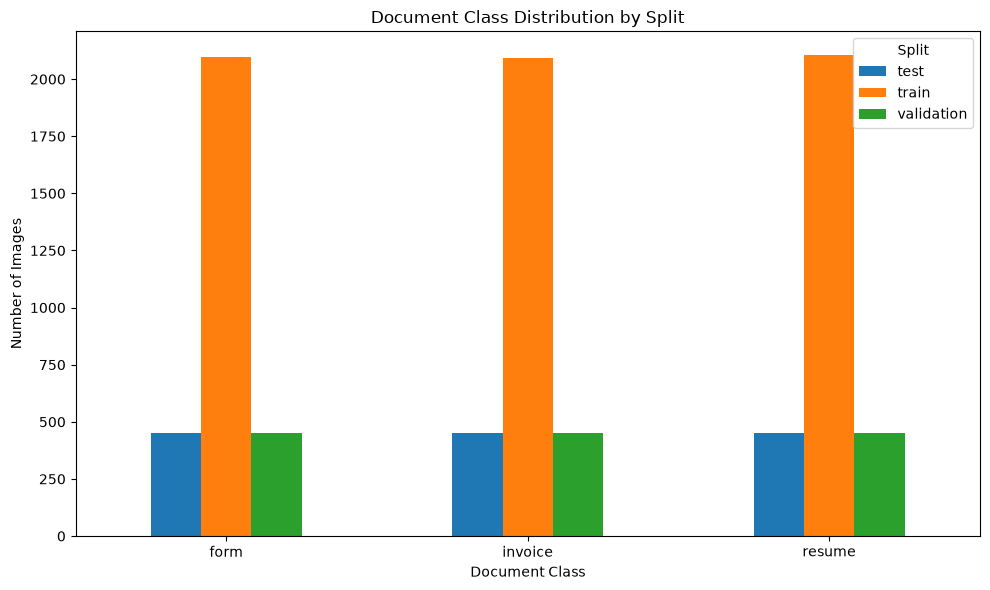


OCR STATISTICS BY SPLIT
     split  documents  empty_text_documents  average_characters  median_characters  average_words  median_words  average_tokens
      test       1349                     2             1368.41             1040.0         199.46         154.0          162.23
     train       6294                     1             1382.41             1033.0         201.10         157.0          164.12
validation       1349                     0             1397.22             1031.0         203.30         155.0          165.75

OCR STATISTICS BY CLASS
     split class_name  documents  empty_text_documents  average_characters  median_characters  average_words  median_words
      test       form        449                     2              971.78              836.0         154.14         132.0
      test    invoice        449                     0              741.75              678.0         117.21         105.0
      test     resume        451                     0             23

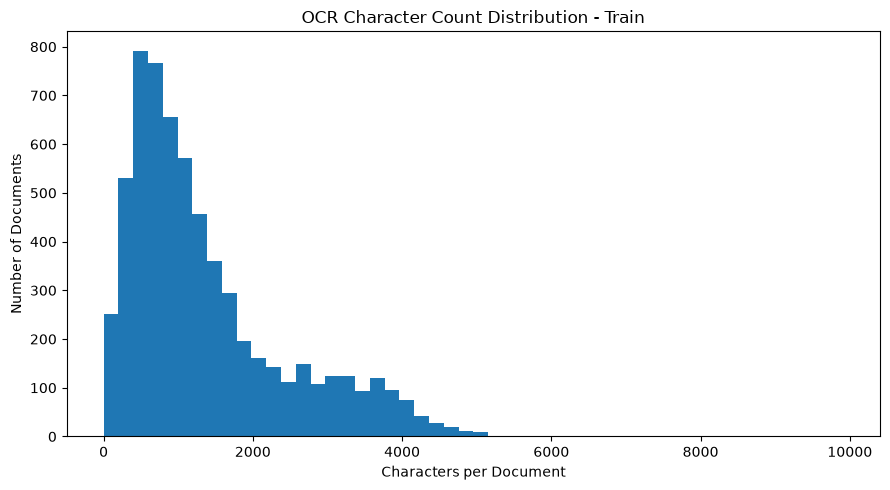

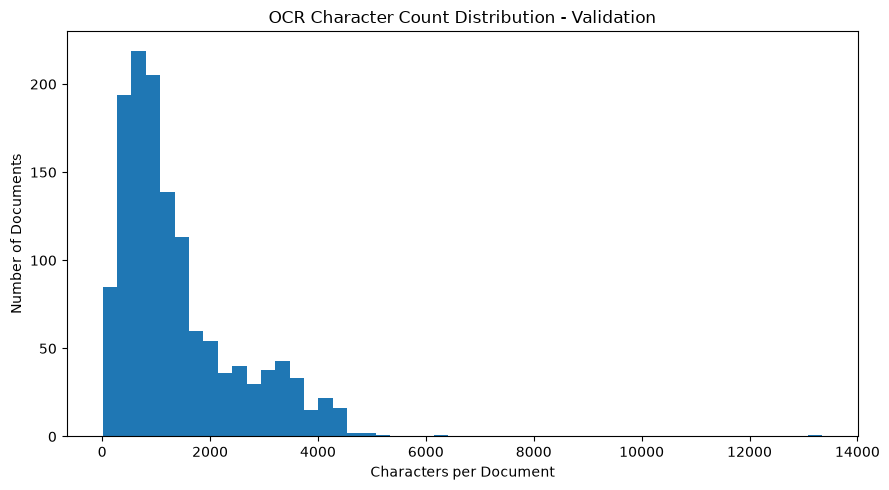

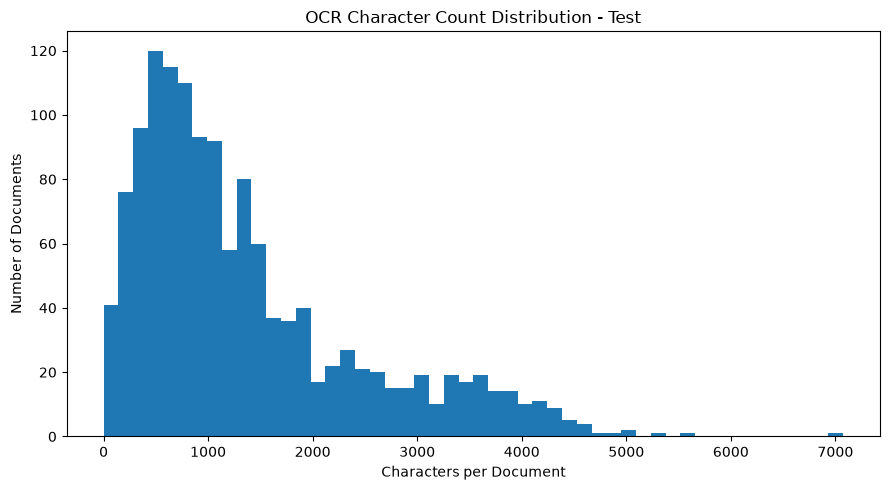

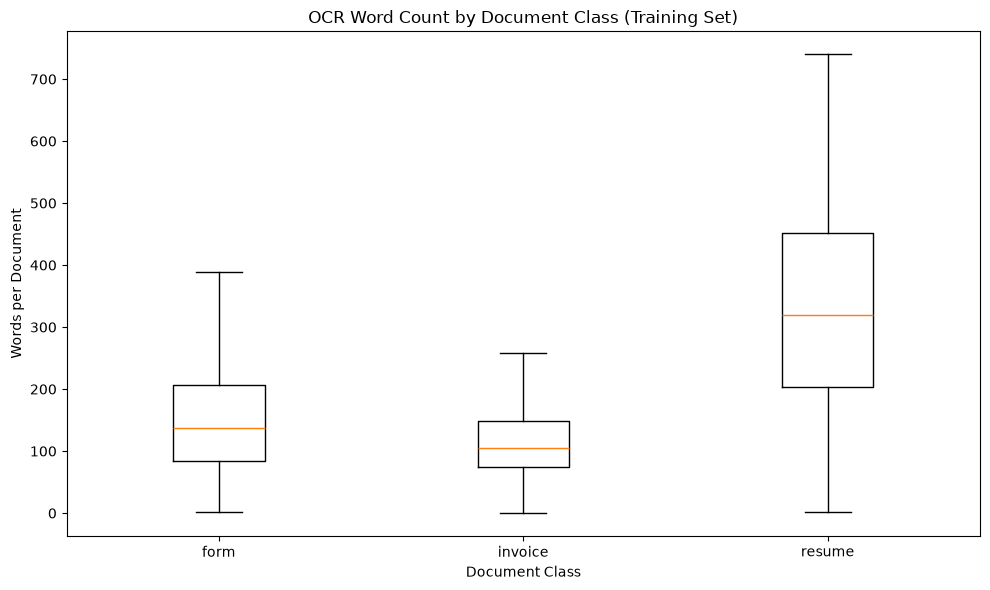


OCR TEXT QUALITY
     split  total_documents  empty_text  text_under_20_characters  text_under_50_characters
     train             6294           1                        26                        62
validation             1349           0                         9                        17
      test             1349           2                         6                        15

Rows flagged for review: 94 (short text is a review flag, not automatically an OCR failure)

DUPLICATE OCR TEXT SUMMARY
{
  "nonempty_documents": 8989,
  "unique_normalized_texts": 8980,
  "duplicate_rows_including_repeated_copies": 16,
  "documents_beyond_first_copy": 9
}

TOP WORDS IN TRAINING OCR TEXT
        word  frequency
  university       9490
    research       7590
    medicine       4157
         new       3881
   professor       3871
  department       3737
     present       3391
     medical       3301
professional       2876
        york       2870
      school       2861
publications       

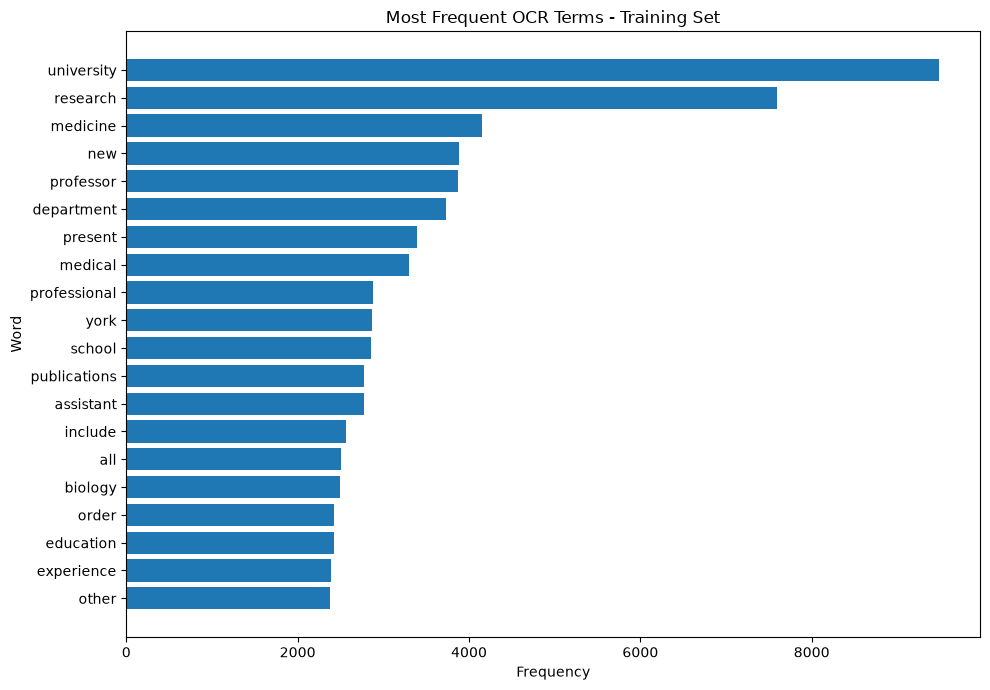


TOP WORDS - FORM
class_name         word  frequency
      form          fax       1248
      form       please       1132
      form          any        892
      form  information        854
      form       morris        794
      form       philip        793
      form         form        791
      form      tobacco        662
      form        total        654
      form        pages        653
      form    telephone        623
      form      company        620
      form         code        607
      form          new        606
      form        other        579
      form          all        579
      form          use        525
      form      product        516
      form         only        514
      form transmission        513


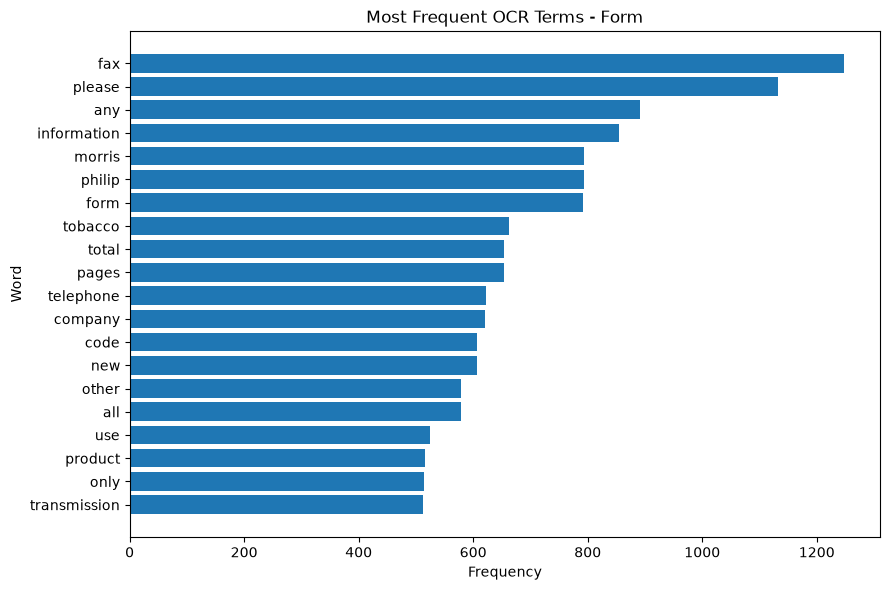


TOP WORDS - INVOICE
class_name      word  frequency
   invoice   invoice       1956
   invoice    amount       1416
   invoice     total       1247
   invoice       new       1202
   invoice       inc       1153
   invoice      york       1111
   invoice       due        872
   invoice       net        753
   invoice       box        707
   invoice     check        639
   invoice    please        615
   invoice lorillard        584
   invoice    avenue        579
   invoice   payment        578
   invoice   tobacco        574
   invoice     order        566
   invoice    street        560
   invoice  research        551
   invoice   company        518
   invoice      code        514


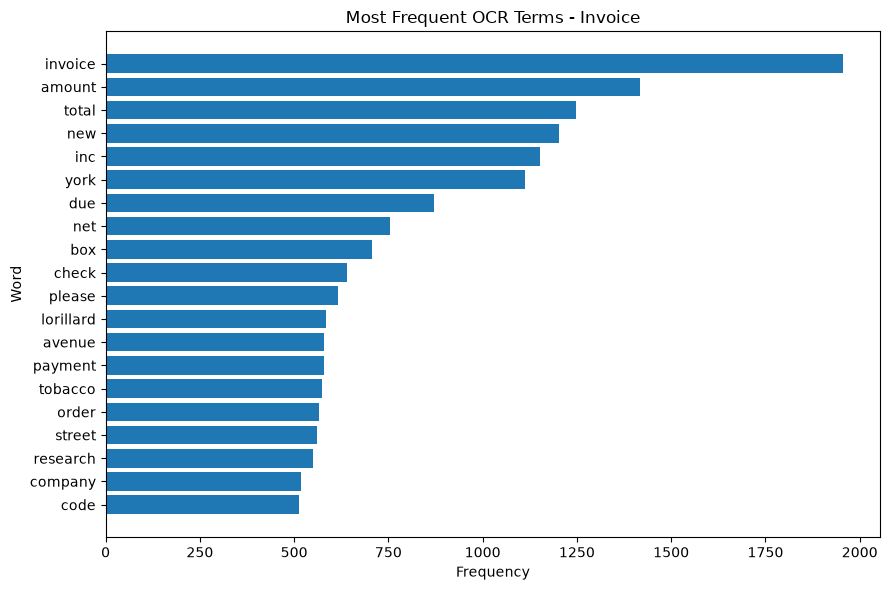


TOP WORDS - RESUME
class_name         word  frequency
    resume   university       9407
    resume     research       6617
    resume     medicine       4117
    resume    professor       3842
    resume      present       3327
    resume      medical       3255
    resume   department       3174
    resume       school       2827
    resume professional       2771
    resume publications       2760
    resume    assistant       2751
    resume      biology       2490
    resume      include       2467
    resume    education       2409
    resume   experience       2360
    resume    associate       2172
    resume         cell       2094
    resume          new       2073
    resume       fellow       2042
    resume    institute       2008


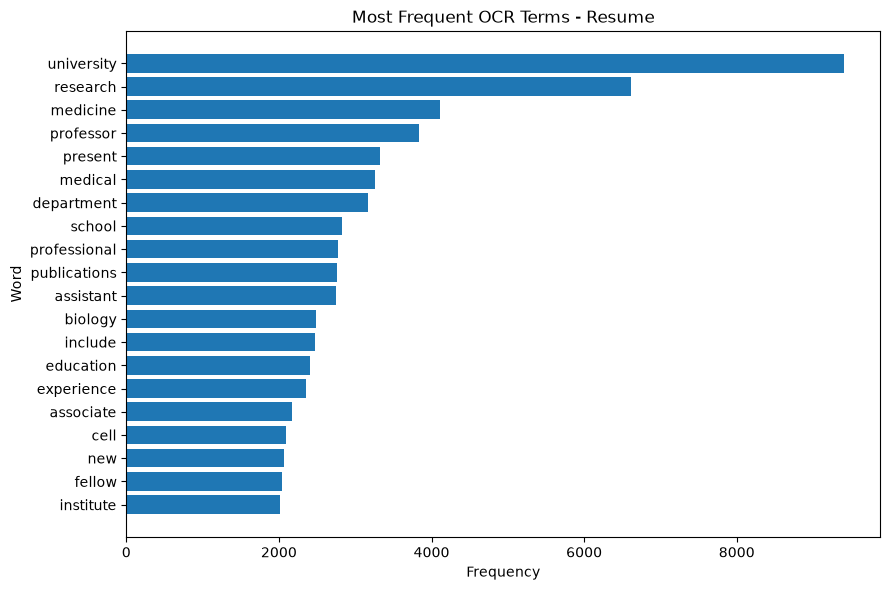


SPLIT / OCR CONSISTENCY
            split_rows  ocr_rows  common_image_paths  class_label_mismatches  split_images_missing_from_ocr  ocr_images_not_in_split
train             6294      6294                6294                       0                              0                        0
validation        1349      1349                1349                       0                              0                        0
test              1349      1349                1349                       0                              0                        0

EDA COMPLETED
EDA output folder: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\eda
Summary JSON:      C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\eda\eda_summary.json
Charts folder:     C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\eda\figures

Generated files include:
 - class_distribution.csv
 - combined_ocr_eda.csv
 - duplicate_ocr_text_rows.csv
 - eda_summary.json
 - figures\character_count_test.png
 - 

In [27]:

from pathlib import Path
import json
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================
DATA_DIR = Path("/content/idp_ml_data")
SPLIT_DIR = DATA_DIR / "splits"
OCR_DIR = Path("idp_outputs") / "ocr"
EDA_DIR = Path("idp_outputs") / "eda"

EDA_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR = EDA_DIR / "figures"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "validation", "test"]
EXPECTED_CLASSES = ["form", "invoice", "resume"]
TOP_N_WORDS = 20

print("=" * 70)
print("INTELLIGENT DOCUMENT PROCESSING SYSTEM - EDA")
print("=" * 70)

# ============================================================
# 2. LOAD EXISTING SPLIT AND OCR CSV FILES
# ============================================================
split_frames = {}
ocr_frames = {}

for split in SPLITS:
    split_path = SPLIT_DIR / f"{split}.csv"
    ocr_path = OCR_DIR / f"{split}_ocr.csv"

    if not split_path.exists():
        raise FileNotFoundError(f"Missing split CSV: {split_path}")
    if not ocr_path.exists():
        raise FileNotFoundError(f"Missing OCR CSV: {ocr_path}")

    split_df = pd.read_csv(split_path)
    ocr_df = pd.read_csv(ocr_path)

    required_split = {"image_path", "class_name"}
    required_ocr = {"image_path", "class_name", "extracted_text"}

    if not required_split.issubset(split_df.columns):
        raise ValueError(
            f"{split_path} must contain columns {required_split}"
        )
    if not required_ocr.issubset(ocr_df.columns):
        raise ValueError(
            f"{ocr_path} must contain columns {required_ocr}"
        )

    split_frames[split] = split_df
    ocr_frames[split] = ocr_df

    print(
        f"{split.title():12s} | split rows: {len(split_df):5d} "
        f"| OCR rows: {len(ocr_df):5d}"
    )

# Use training data to define the classes.
classes = sorted(
    split_frames["train"]["class_name"].dropna().astype(str).unique()
)
print("\nClasses:", classes)

# ============================================================
# 3. COMBINE OCR DATA AND BASIC DATA QUALITY CHECKS
# ============================================================
all_ocr = []

for split in SPLITS:
    df = ocr_frames[split].copy()
    df["split"] = split
    df["extracted_text"] = df["extracted_text"].fillna("").astype(str)
    all_ocr.append(df)

combined = pd.concat(all_ocr, ignore_index=True)

# Normalize whitespace for measurement only; preserve original text.
combined["text_clean"] = (
    combined["extracted_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
combined["char_count"] = combined["text_clean"].str.len()
combined["word_count"] = combined["text_clean"].apply(
    lambda text: len(text.split()) if text else 0
)
combined["empty_text"] = combined["text_clean"].eq("")

# Basic word tokens for exploratory analysis.
def tokenize(text):
    return re.findall(r"\b[a-zA-Z]{2,}\b", str(text).lower())

combined["tokens"] = combined["text_clean"].apply(tokenize)
combined["token_count"] = combined["tokens"].str.len()

# Save combined EDA dataset.
combined.drop(columns=["tokens"]).to_csv(
    EDA_DIR / "combined_ocr_eda.csv", index=False
)

# ============================================================
# 4. CLASS DISTRIBUTION
# ============================================================
class_rows = []

for split in SPLITS:
    counts = (
        split_frames[split]["class_name"]
        .value_counts()
        .reindex(classes, fill_value=0)
    )

    for label, count in counts.items():
        class_rows.append({
            "split": split,
            "class_name": label,
            "image_count": int(count),
            "percentage": round(
                100 * count / max(len(split_frames[split]), 1), 2
            )
        })

class_distribution = pd.DataFrame(class_rows)
class_distribution.to_csv(
    EDA_DIR / "class_distribution.csv", index=False
)

print("\nCLASS DISTRIBUTION")
print(
    class_distribution.pivot(
        index="class_name", columns="split", values="image_count"
    ).to_string()
)

pivot_counts = class_distribution.pivot(
    index="class_name", columns="split", values="image_count"
).reindex(classes)

ax = pivot_counts.plot(kind="bar", figsize=(10, 6))
ax.set_title("Document Class Distribution by Split")
ax.set_xlabel("Document Class")
ax.set_ylabel("Number of Images")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Split")
plt.tight_layout()
plt.savefig(PLOT_DIR / "class_distribution.png", dpi=160)
plt.show()
plt.close()

# ============================================================
# 5. OCR TEXT STATISTICS BY SPLIT AND CLASS
# ============================================================
split_stats = (
    combined.groupby("split")
    .agg(
        documents=("image_path", "size"),
        empty_text_documents=("empty_text", "sum"),
        average_characters=("char_count", "mean"),
        median_characters=("char_count", "median"),
        average_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        average_tokens=("token_count", "mean")
    )
    .reset_index()
)

numeric_cols = split_stats.select_dtypes(include="number").columns
split_stats[numeric_cols] = split_stats[numeric_cols].round(2)
split_stats.to_csv(EDA_DIR / "ocr_statistics_by_split.csv", index=False)

class_stats = (
    combined.groupby(["split", "class_name"])
    .agg(
        documents=("image_path", "size"),
        empty_text_documents=("empty_text", "sum"),
        average_characters=("char_count", "mean"),
        median_characters=("char_count", "median"),
        average_words=("word_count", "mean"),
        median_words=("word_count", "median")
    )
    .reset_index()
)

class_stats = class_stats.round(2)
class_stats.to_csv(
    EDA_DIR / "ocr_statistics_by_class.csv", index=False
)

print("\nOCR STATISTICS BY SPLIT")
print(split_stats.to_string(index=False))

print("\nOCR STATISTICS BY CLASS")
print(class_stats.to_string(index=False))

# Character-count distributions.
for split in SPLITS:
    subset = combined.loc[combined["split"] == split, "char_count"]

    plt.figure(figsize=(9, 5))
    plt.hist(subset, bins=50)
    plt.title(f"OCR Character Count Distribution - {split.title()}")
    plt.xlabel("Characters per Document")
    plt.ylabel("Number of Documents")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"character_count_{split}.png", dpi=160)
    plt.show()
    plt.close()

# Compare word counts by class.
plt.figure(figsize=(10, 6))
box_data = [
    combined.loc[
        (combined["split"] == "train") &
        (combined["class_name"] == label),
        "word_count"
    ].values
    for label in classes
]
plt.boxplot(box_data, tick_labels=classes, showfliers=False)
plt.title("OCR Word Count by Document Class (Training Set)")
plt.xlabel("Document Class")
plt.ylabel("Words per Document")
plt.tight_layout()
plt.savefig(PLOT_DIR / "word_count_by_class.png", dpi=160)
plt.show()
plt.close()

# ============================================================
# 6. EMPTY AND UNUSUALLY SHORT OCR TEXT
# ============================================================
short_threshold = 20

quality_rows = []
for split in SPLITS:
    subset = combined[combined["split"] == split]

    quality_rows.append({
        "split": split,
        "total_documents": int(len(subset)),
        "empty_text": int(subset["empty_text"].sum()),
        "text_under_20_characters": int(
            (subset["char_count"] < short_threshold).sum()
        ),
        "text_under_50_characters": int(
            (subset["char_count"] < 50).sum()
        )
    })

quality_report = pd.DataFrame(quality_rows)
quality_report.to_csv(
    EDA_DIR / "ocr_text_quality.csv", index=False
)

print("\nOCR TEXT QUALITY")
print(quality_report.to_string(index=False))

# Save rows requiring manual inspection.
quality_flags = combined[
    (combined["char_count"] < 50) |
    (combined["empty_text"])
].copy()

quality_flags.drop(columns=["tokens"]).to_csv(
    EDA_DIR / "ocr_rows_for_review.csv", index=False
)

print(
    "\nRows flagged for review:",
    len(quality_flags),
    "(short text is a review flag, not automatically an OCR failure)"
)

# ============================================================
# 7. DUPLICATE OCR TEXT ANALYSIS
# ============================================================
# Exact duplicates after whitespace normalization.
nonempty = combined[combined["text_clean"].ne("")].copy()

duplicate_mask = nonempty.duplicated(
    subset=["text_clean"], keep=False
)
duplicate_rows = nonempty.loc[duplicate_mask].copy()

duplicate_summary = {
    "nonempty_documents": int(len(nonempty)),
    "unique_normalized_texts": int(nonempty["text_clean"].nunique()),
    "duplicate_rows_including_repeated_copies": int(duplicate_mask.sum()),
    "documents_beyond_first_copy": int(
        nonempty.duplicated(subset=["text_clean"], keep="first").sum()
    )
}

duplicate_rows.drop(columns=["tokens"]).to_csv(
    EDA_DIR / "duplicate_ocr_text_rows.csv", index=False
)

print("\nDUPLICATE OCR TEXT SUMMARY")
print(json.dumps(duplicate_summary, indent=2))

# ============================================================
# 8. TOP WORDS OVERALL AND BY CLASS
# ============================================================
# Deliberately lightweight stopword list for EDA only.
# Do not apply this automatically to the eventual model input.
stopwords = set("""
a an the and or but if then else of in on at to for from by with
is are was were be been being it this that these those as into
about over under between during after before not no yes we you they
he she them his her their our your its can could would should will
may might must have has had do does did done document page name
address date number phone email
""".split())

def top_words(texts, n=TOP_N_WORDS):
    counts = Counter()
    for text in texts:
        counts.update(
            token for token in tokenize(text)
            if token not in stopwords
        )
    return counts.most_common(n)

overall_top = top_words(combined.loc[
    combined["split"] == "train", "text_clean"
])

overall_df = pd.DataFrame(
    overall_top, columns=["word", "frequency"]
)
overall_df.to_csv(EDA_DIR / "top_words_train_overall.csv", index=False)

print("\nTOP WORDS IN TRAINING OCR TEXT")
print(overall_df.to_string(index=False))

if not overall_df.empty:
    plt.figure(figsize=(10, 7))
    plot_df = overall_df.sort_values("frequency")
    plt.barh(plot_df["word"], plot_df["frequency"])
    plt.title("Most Frequent OCR Terms - Training Set")
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "top_words_overall.png", dpi=160)
    plt.show()
    plt.close()

# Class-specific term frequencies using only training documents.
class_word_tables = []

for label in classes:
    texts = combined.loc[
        (combined["split"] == "train") &
        (combined["class_name"] == label),
        "text_clean"
    ]

    words = top_words(texts)
    for word, frequency in words:
        class_word_tables.append({
            "class_name": label,
            "word": word,
            "frequency": int(frequency)
        })

class_word_df = pd.DataFrame(class_word_tables)
class_word_df.to_csv(
    EDA_DIR / "top_words_by_class.csv", index=False
)

for label in classes:
    subset = class_word_df[class_word_df["class_name"] == label]
    if subset.empty:
        continue

    print(f"\nTOP WORDS - {label.upper()}")
    print(subset.to_string(index=False))

    plot_df = subset.sort_values("frequency")
    plt.figure(figsize=(9, 6))
    plt.barh(plot_df["word"], plot_df["frequency"])
    plt.title(f"Most Frequent OCR Terms - {label.title()}")
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"top_words_{label}.png", dpi=160)
    plt.show()
    plt.close()

# ============================================================
# 9. LABEL AND OCR ROW CONSISTENCY
# ============================================================
consistency = {}

for split in SPLITS:
    split_df = split_frames[split].copy()
    ocr_df = ocr_frames[split].copy()

    # Compare path-to-label mappings, rather than row order.
    split_map = (
        split_df.dropna(subset=["image_path"])
        .assign(image_path=lambda x: x["image_path"].astype(str))
        .drop_duplicates("image_path")
        .set_index("image_path")["class_name"]
    )

    ocr_map = (
        ocr_df.dropna(subset=["image_path"])
        .assign(image_path=lambda x: x["image_path"].astype(str))
        .drop_duplicates("image_path")
        .set_index("image_path")["class_name"]
    )

    common_paths = split_map.index.intersection(ocr_map.index)
    mismatch_count = int(
        (split_map.loc[common_paths].astype(str) !=
         ocr_map.loc[common_paths].astype(str)).sum()
    )

    consistency[split] = {
        "split_rows": int(len(split_df)),
        "ocr_rows": int(len(ocr_df)),
        "common_image_paths": int(len(common_paths)),
        "class_label_mismatches": mismatch_count,
        "split_images_missing_from_ocr": int(
            len(set(split_map.index) - set(ocr_map.index))
        ),
        "ocr_images_not_in_split": int(
            len(set(ocr_map.index) - set(split_map.index))
        )
    }

consistency_df = pd.DataFrame(consistency).T
consistency_df.to_csv(
    EDA_DIR / "split_ocr_consistency.csv", index_label="split"
)

print("\nSPLIT / OCR CONSISTENCY")
print(consistency_df.to_string())

# ============================================================
# 10. SAVE FINAL EDA SUMMARY
# ============================================================
summary = {
    "project": "Intelligent Document Processing System",
    "classes": classes,
    "total_split_documents": {
        split: int(len(split_frames[split])) for split in SPLITS
    },
    "total_ocr_rows": int(len(combined)),
    "empty_ocr_rows": int(combined["empty_text"].sum()),
    "documents_under_20_characters": int(
        (combined["char_count"] < 20).sum()
    ),
    "duplicate_text_summary": duplicate_summary,
    "class_distribution": class_distribution.to_dict(orient="records"),
    "ocr_statistics_by_split": split_stats.to_dict(orient="records"),
    "split_ocr_consistency": consistency,
    "notes": [
        "EDA term-frequency analysis uses training OCR text only.",
        "Validation and test text are not used to choose model features.",
        "Short text and exact duplicate text are inspection flags, not proof of errors.",
        "No OCR, split generation, or model training was run in this cell."
    ]
}

summary_path = EDA_DIR / "eda_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=str)

print("\n" + "=" * 70)
print("EDA COMPLETED")
print("=" * 70)
print(f"EDA output folder: {EDA_DIR.resolve()}")
print(f"Summary JSON:      {summary_path.resolve()}")
print(f"Charts folder:     {PLOT_DIR.resolve()}")
print("\nGenerated files include:")
for path in sorted(EDA_DIR.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(EDA_DIR))

print("\nNext stage: TF-IDF feature extraction and traditional ML models.")


**TF-IDF**

In [28]:

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
from scipy.sparse import save_npz
from sklearn.feature_extraction.text import TfidfVectorizer

# ============================================================
# 1. PATHS
# ============================================================
OCR_DIR = Path("idp_outputs") / "ocr"
TFIDF_DIR = Path("idp_outputs") / "tfidf"
TFIDF_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "validation", "test"]

# ============================================================
# 2. LOAD EXISTING OCR DATA
# ============================================================
frames = {}

for split in SPLITS:
    path = OCR_DIR / f"{split}_ocr.csv"

    if not path.exists():
        raise FileNotFoundError(f"OCR CSV not found: {path.resolve()}")

    df = pd.read_csv(path)

    required = {"image_path", "class_name", "extracted_text"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path.name} is missing columns: {missing}")

    df["extracted_text"] = df["extracted_text"].fillna("").astype(str)
    frames[split] = df

    print(f"{split.title()}: {len(df)} OCR records loaded")

# ============================================================
# 3. CHECK CLASS LABELS AND MATCHING SPLIT ROWS
# ============================================================
classes = sorted(
    frames["train"]["class_name"].dropna().astype(str).unique()
)

if len(classes) < 2:
    raise ValueError(f"Expected multiple classes; found {classes}")

class_to_id = {label: idx for idx, label in enumerate(classes)}

for split, df in frames.items():
    unknown = set(df["class_name"].dropna().astype(str)) - set(classes)
    if unknown:
        raise ValueError(f"Unknown labels in {split}: {unknown}")

    if df["class_name"].isna().any():
        raise ValueError(f"Missing class labels in {split}")

print("\nClasses:", classes)

# ============================================================
# 4. FIT TF-IDF ON TRAINING TEXT ONLY
# ============================================================
# Keep OCR text as-is apart from filling missing values.
# max_features controls vocabulary size.
# ngram_range=(1, 2) includes unigrams and bigrams.
vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    dtype=np.float32
)

X_train = vectorizer.fit_transform(frames["train"]["extracted_text"])

# Transform other splits using the training vocabulary.
X_validation = vectorizer.transform(
    frames["validation"]["extracted_text"]
)
X_test = vectorizer.transform(
    frames["test"]["extracted_text"]
)

# Integer-encoded labels in the same class order.
y_train = frames["train"]["class_name"].astype(str).map(class_to_id).to_numpy()
y_validation = frames["validation"]["class_name"].astype(str).map(class_to_id).to_numpy()
y_test = frames["test"]["class_name"].astype(str).map(class_to_id).to_numpy()

# ============================================================
# 5. DISPLAY FEATURE INFORMATION
# ============================================================
print("\n" + "=" * 60)
print("TF-IDF FEATURE EXTRACTION RESULTS")
print("=" * 60)

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_validation, y_validation),
    ("Test", X_test, y_test)
]:
    print(
        f"{name:12s}: samples={X.shape[0]:5d}, "
        f"features={X.shape[1]:5d}, "
        f"labels={len(y):5d}, "
        f"sparsity={100 * (1 - X.nnz / max(X.shape[0] * X.shape[1], 1)):.2f}%"
    )

print("\nClass mapping:", class_to_id)
print("Vocabulary size:", len(vectorizer.vocabulary_))

# Show a few learned features.
feature_names = vectorizer.get_feature_names_out()
print("\nFirst 30 features:")
print(feature_names[:30].tolist())

# ============================================================
# 6. SAVE FEATURES, LABELS, AND VECTORIZER
# ============================================================
save_npz(TFIDF_DIR / "X_train.npz", X_train)
save_npz(TFIDF_DIR / "X_validation.npz", X_validation)
save_npz(TFIDF_DIR / "X_test.npz", X_test)

np.save(TFIDF_DIR / "y_train.npy", y_train)
np.save(TFIDF_DIR / "y_validation.npy", y_validation)
np.save(TFIDF_DIR / "y_test.npy", y_test)

joblib.dump(vectorizer, TFIDF_DIR / "tfidf_vectorizer.joblib")

with open(TFIDF_DIR / "class_mapping.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "classes": classes,
            "class_to_id": class_to_id,
            "id_to_class": {str(v): k for k, v in class_to_id.items()},
            "vocabulary_size": len(vectorizer.vocabulary_),
            "max_features": 20000,
            "ngram_range": [1, 2],
            "min_df": 2
        },
        f,
        indent=2
    )

# Save a readable feature summary.
summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "samples": [X_train.shape[0], X_validation.shape[0], X_test.shape[0]],
    "features": [X_train.shape[1], X_validation.shape[1], X_test.shape[1]],
    "nonzero_values": [X_train.nnz, X_validation.nnz, X_test.nnz]
})
summary.to_csv(TFIDF_DIR / "tfidf_summary.csv", index=False)

print("\nTF-IDF completed successfully.")
print("Output folder:", TFIDF_DIR.resolve())
print("\nSaved files:")
for path in sorted(TFIDF_DIR.iterdir()):
    if path.is_file():
        print(" -", path.name)


Train: 6294 OCR records loaded
Validation: 1349 OCR records loaded
Test: 1349 OCR records loaded

Classes: ['form', 'invoice', 'resume']

TF-IDF FEATURE EXTRACTION RESULTS
Train       : samples= 6294, features=20000, labels= 6294, sparsity=99.19%
Validation  : samples= 1349, features=20000, labels= 1349, sparsity=99.21%
Test        : samples= 1349, features=20000, labels= 1349, sparsity=99.22%

Class mapping: {'form': 0, 'invoice': 1, 'resume': 2}
Vocabulary size: 20000

First 30 features:
['00', '00 00', '00 000', '00 01', '00 02', '00 06', '00 09', '00 10', '00 100', '00 11', '00 12', '00 13', '00 14', '00 15', '00 150', '00 16', '00 18', '00 20', '00 200', '00 21', '00 23', '00 25', '00 250', '00 2500', '00 30', '00 300', '00 31', '00 35', '00 40', '00 50']

TF-IDF completed successfully.
Output folder: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\tfidf

Saved files:
 - class_mapping.json
 - tfidf_summary.csv
 - tfidf_vectorizer.joblib
 - X_test.npz
 - X_train.npz
 - X_va

**MACHINE LEARNING**

**Common setup and evaluation function**

In [33]:

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import load_npz
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Load existing TF-IDF data
BASE = Path("idp_outputs") / "tfidf"
RESULTS = Path("idp_outputs") / "traditional_ml"
RESULTS.mkdir(parents=True, exist_ok=True)

X_train = load_npz(BASE / "X_train.npz")
X_val = load_npz(BASE / "X_validation.npz")
X_test = load_npz(BASE / "X_test.npz")

y_train = np.load(BASE / "y_train.npy")
y_val = np.load(BASE / "y_validation.npy")
y_test = np.load(BASE / "y_test.npy")

with open(BASE / "class_mapping.json", encoding="utf-8") as f:
    mapping = json.load(f)

classes = mapping["classes"]
class_ids = list(range(len(classes)))

print("TF-IDF data loaded successfully.")
print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Test samples:", X_test.shape[0])
print("Classes:", classes)


def evaluate_model(name, model):
    # Train model
    model.fit(X_train, y_train)

    # Validation predictions
    pred = model.predict(X_val)

    # Calculate metrics
    accuracy = accuracy_score(y_val, pred)

    precision, recall, _, _ = precision_recall_fscore_support(
        y_val, pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_val, pred,
        average="macro",
        zero_division=0
    )

    print("\n" + "=" * 60)
    print(name)
    print(f"Validation Accuracy : {accuracy:.2%}")
    print(f"Validation Precision: {precision:.4f}")
    print(f"Validation Recall   : {recall:.4f}")
    print(f"Validation Macro F1 : {macro_f1:.4f}")

    # Classification report
    print("\nClassification Report:")
    print(classification_report(
        y_val,
        pred,
        labels=class_ids,
        target_names=classes,
        zero_division=0
    ))

    # Explicit exact accuracy line
    print(f"Exact Validation Accuracy: {accuracy:.2%}")
    print(f"Correct predictions: {int((pred == y_val).sum())}/{len(y_val)}")

    file_prefix = name.lower().replace(" ", "_")

    # GRAPH 1: Confusion matrix heatmap
    cm = confusion_matrix(y_val, pred, labels=class_ids)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        RESULTS / f"{file_prefix}_confusion_matrix.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # GRAPH 2: Validation accuracy
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar([name], [accuracy])
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("Accuracy")
    ax.set_title(f"{name} - Validation Accuracy")
    ax.bar_label(bars, labels=[f"{accuracy:.2%}"], padding=4)
    plt.tight_layout()
    plt.savefig(
        RESULTS / f"{file_prefix}_accuracy.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # GRAPH 3: Precision, recall and F1-score by class
    report = classification_report(
        y_val,
        pred,
        labels=class_ids,
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    metric_df = pd.DataFrame({
        "Precision": [report[c]["precision"] for c in classes],
        "Recall": [report[c]["recall"] for c in classes],
        "F1-score": [report[c]["f1-score"] for c in classes]
    }, index=classes)

    ax = metric_df.plot(
        kind="bar",
        figsize=(9, 5),
        ylim=(0, 1.08)
    )
    ax.set_title(f"{name} - Per-Class Performance")
    ax.set_ylabel("Score")
    ax.set_xlabel("Document Class")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(
        RESULTS / f"{file_prefix}_class_metrics.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # Save trained model
    joblib.dump(model, RESULTS / f"{file_prefix}.joblib")

    return {
        "model": name,
        "validation_accuracy": accuracy,
        "validation_precision_macro": precision,
        "validation_recall_macro": recall,
        "validation_macro_f1": macro_f1,
        "predictions": pred,
        "estimator": model
    }


print("\nEvaluation function ready.")


TF-IDF data loaded successfully.
Training samples: 6294
Validation samples: 1349
Test samples: 1349
Classes: ['form', 'invoice', 'resume']

Evaluation function ready.


**LOGISTIC REGRESSION**


Logistic Regression
Validation Accuracy : 95.03%
Validation Precision: 0.9507
Validation Recall   : 0.9503
Validation Macro F1 : 0.9505

Classification Report:
              precision    recall  f1-score   support

        form       0.92      0.94      0.93       449
     invoice       0.94      0.93      0.93       449
      resume       1.00      0.98      0.99       451

    accuracy                           0.95      1349
   macro avg       0.95      0.95      0.95      1349
weighted avg       0.95      0.95      0.95      1349

Exact Validation Accuracy: 95.03%
Correct predictions: 1282/1349


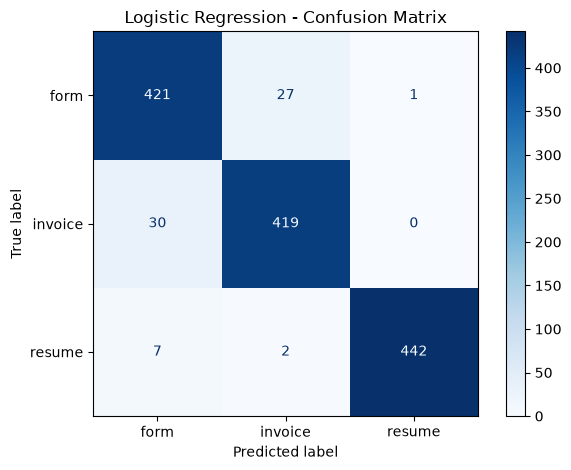

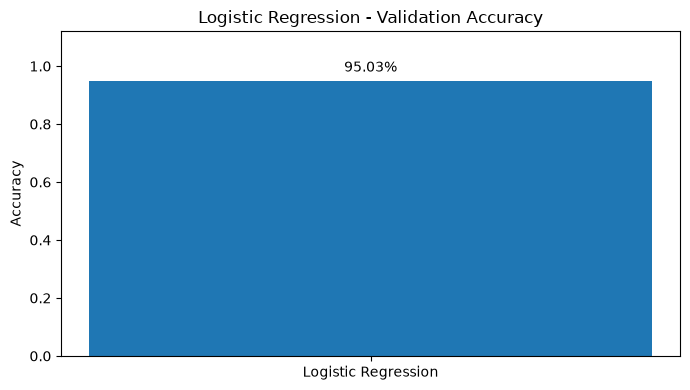

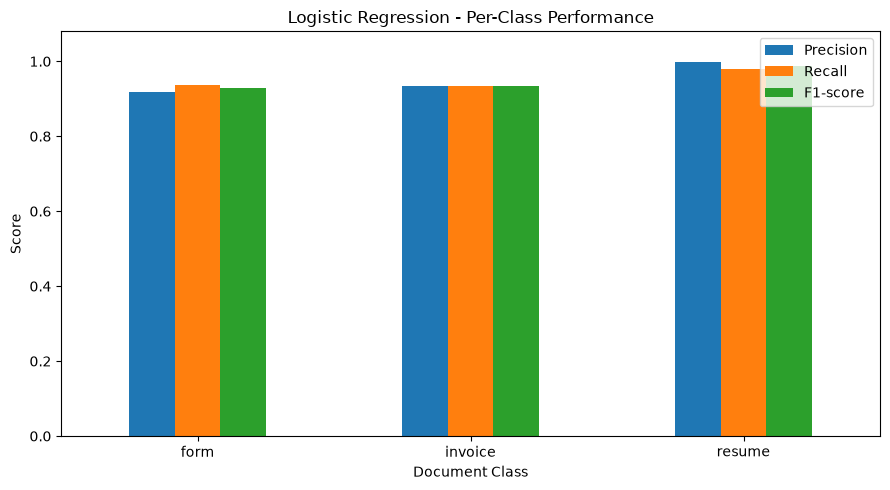

In [34]:


from sklearn.linear_model import LogisticRegression

lr_result = evaluate_model(
    "Logistic Regression",
    LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    )
)


**Multinomial Naive Bayes**


Multinomial Naive Bayes
Validation Accuracy : 93.18%
Validation Precision: 0.9323
Validation Recall   : 0.9317
Validation Macro F1 : 0.9317

Classification Report:
              precision    recall  f1-score   support

        form       0.92      0.88      0.90       449
     invoice       0.90      0.95      0.92       449
      resume       0.98      0.97      0.97       451

    accuracy                           0.93      1349
   macro avg       0.93      0.93      0.93      1349
weighted avg       0.93      0.93      0.93      1349

Exact Validation Accuracy: 93.18%
Correct predictions: 1257/1349


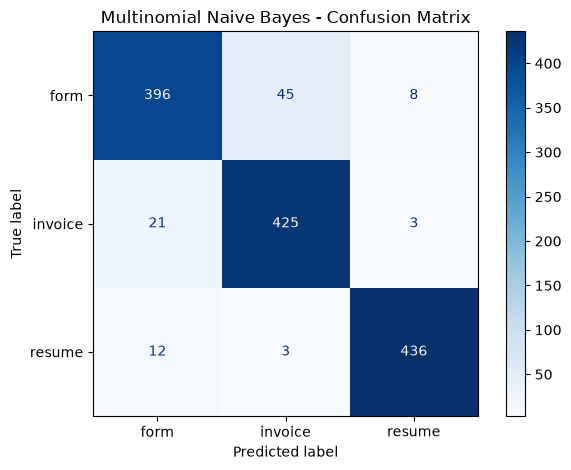

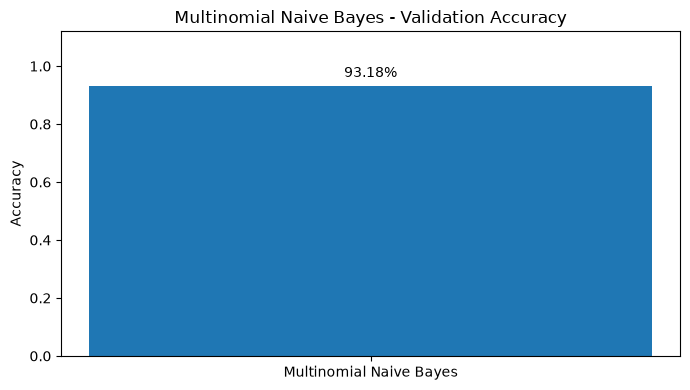

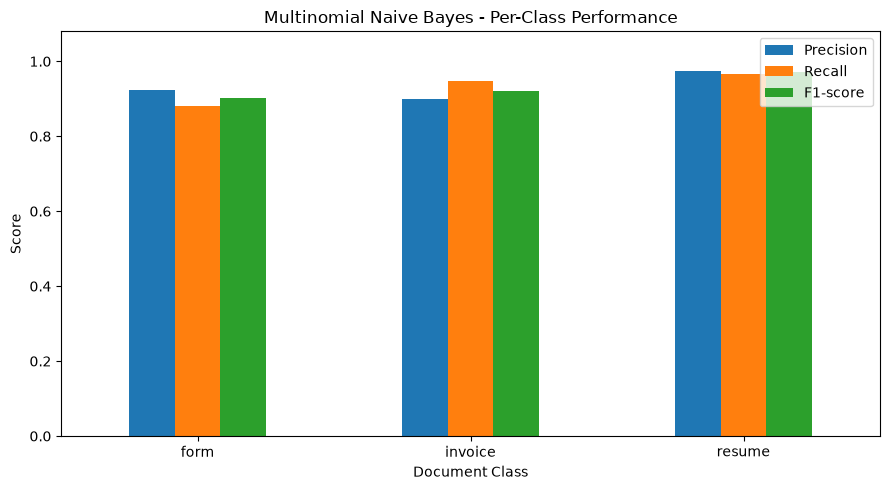

In [35]:

from sklearn.naive_bayes import MultinomialNB

nb_result = evaluate_model(
    "Multinomial Naive Bayes",
    MultinomialNB(alpha=0.5)
)


**Linear SVM**


Linear SVM
Validation Accuracy : 95.18%
Validation Precision: 0.9521
Validation Recall   : 0.9518
Validation Macro F1 : 0.9519

Classification Report:
              precision    recall  f1-score   support

        form       0.93      0.94      0.93       449
     invoice       0.93      0.94      0.93       449
      resume       1.00      0.98      0.99       451

    accuracy                           0.95      1349
   macro avg       0.95      0.95      0.95      1349
weighted avg       0.95      0.95      0.95      1349

Exact Validation Accuracy: 95.18%
Correct predictions: 1284/1349


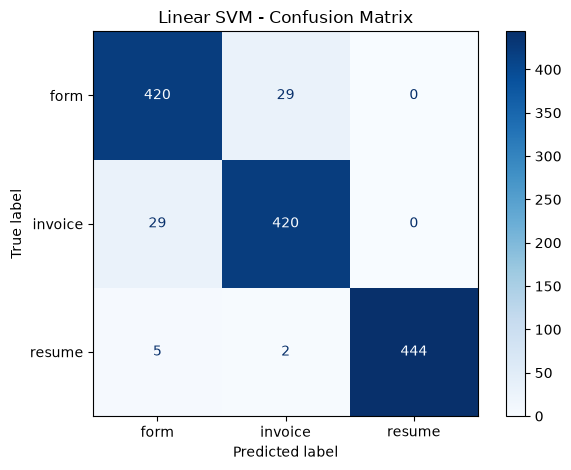

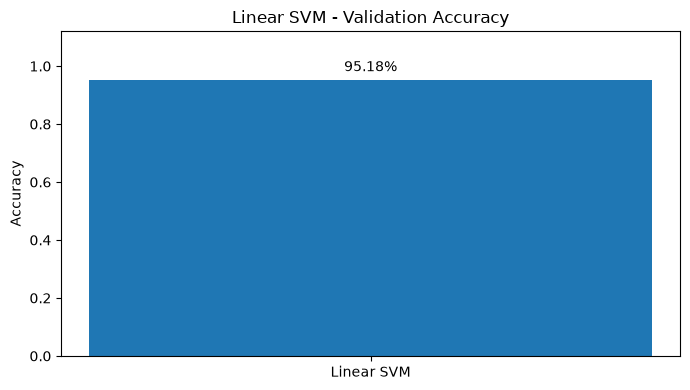

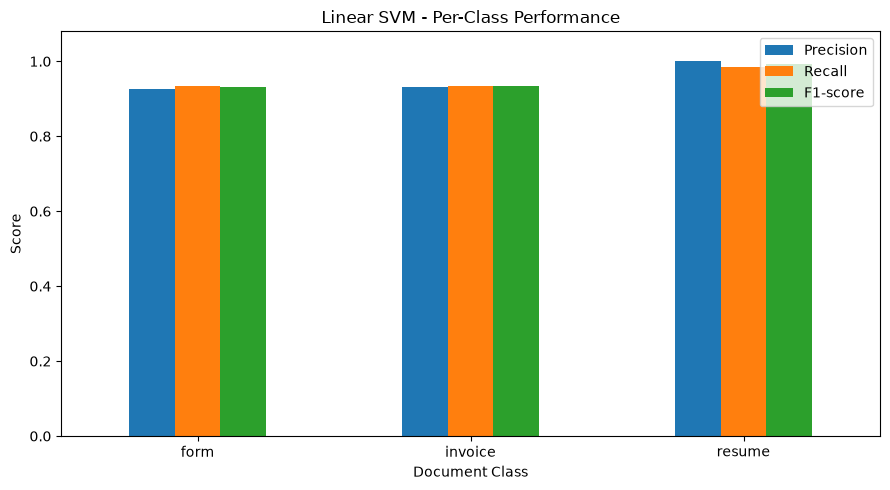

In [36]:

from sklearn.svm import LinearSVC

svm_result = evaluate_model(
    "Linear SVM",
    LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    )
)


**KNN with cosine distance**


KNN Cosine
Validation Accuracy : 93.70%
Validation Precision: 0.9374
Validation Recall   : 0.9369
Validation Macro F1 : 0.9371

Classification Report:
              precision    recall  f1-score   support

        form       0.91      0.92      0.92       449
     invoice       0.92      0.92      0.92       449
      resume       0.99      0.97      0.98       451

    accuracy                           0.94      1349
   macro avg       0.94      0.94      0.94      1349
weighted avg       0.94      0.94      0.94      1349

Exact Validation Accuracy: 93.70%
Correct predictions: 1264/1349


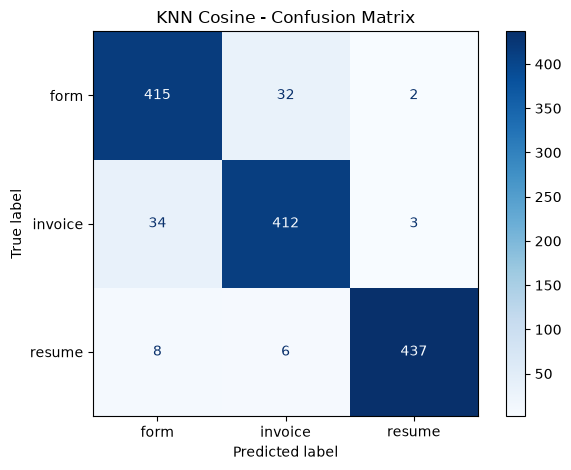

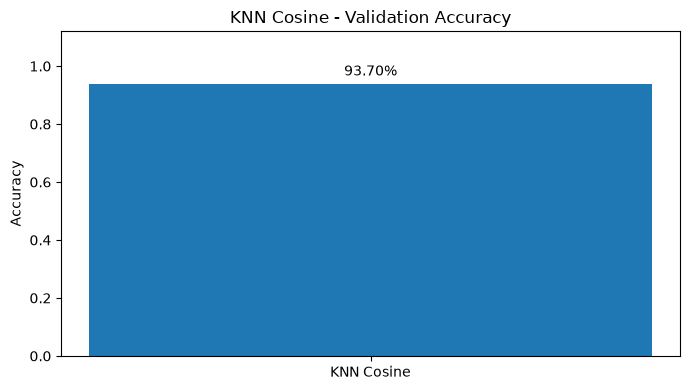

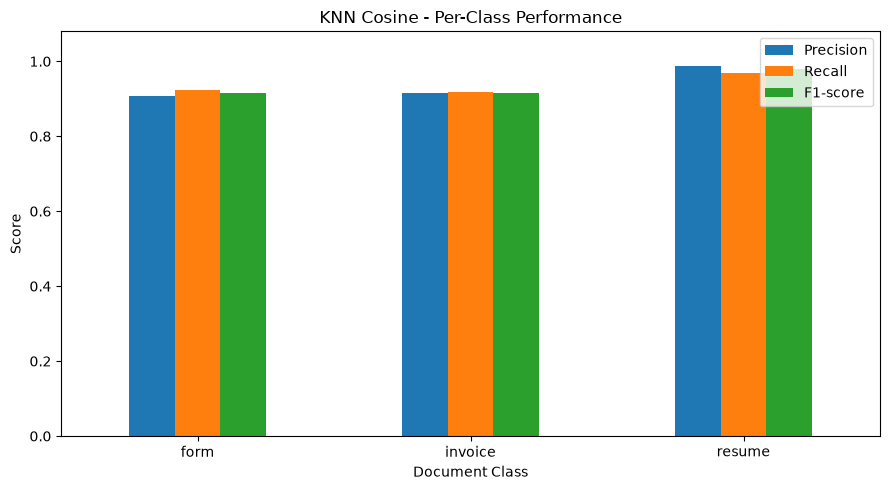

In [37]:

from sklearn.neighbors import KNeighborsClassifier

knn_result = evaluate_model(
    "KNN Cosine",
    KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        weights="distance",
        n_jobs=-1
    )
)


**Compare all four algorithms**

VALIDATION PERFORMANCE COMPARISON
              Algorithm Accuracy Macro Precision Macro Recall Macro F1
             Linear SVM   95.18%          0.9521       0.9518   0.9519
    Logistic Regression   95.03%          0.9507       0.9503   0.9505
             KNN Cosine   93.70%          0.9374       0.9369   0.9371
Multinomial Naive Bayes   93.18%          0.9323       0.9317   0.9317


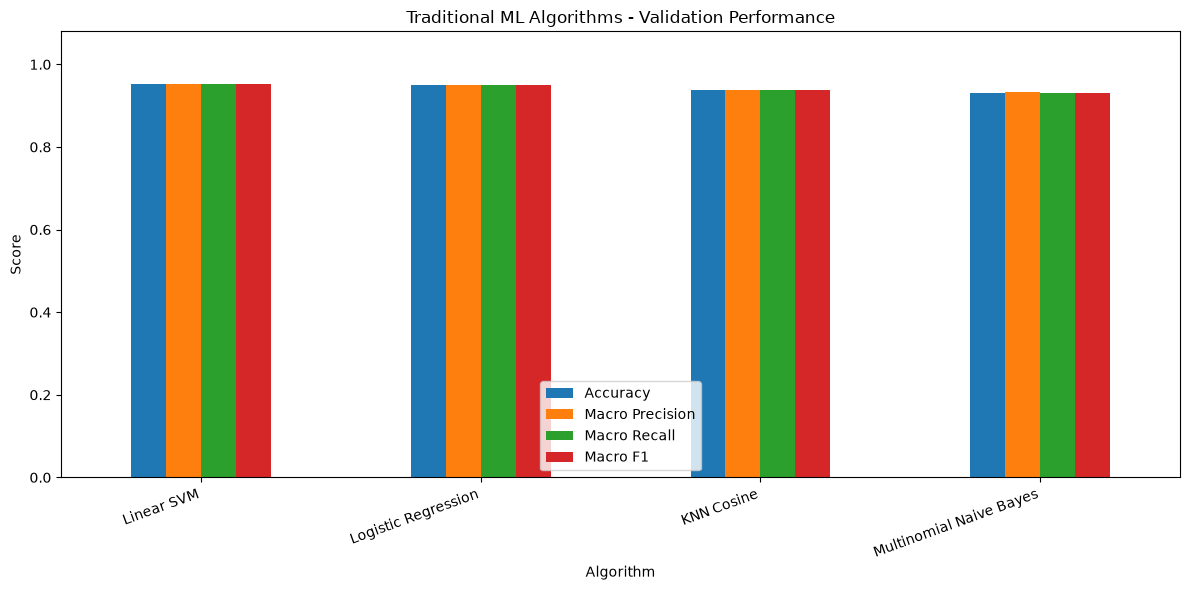

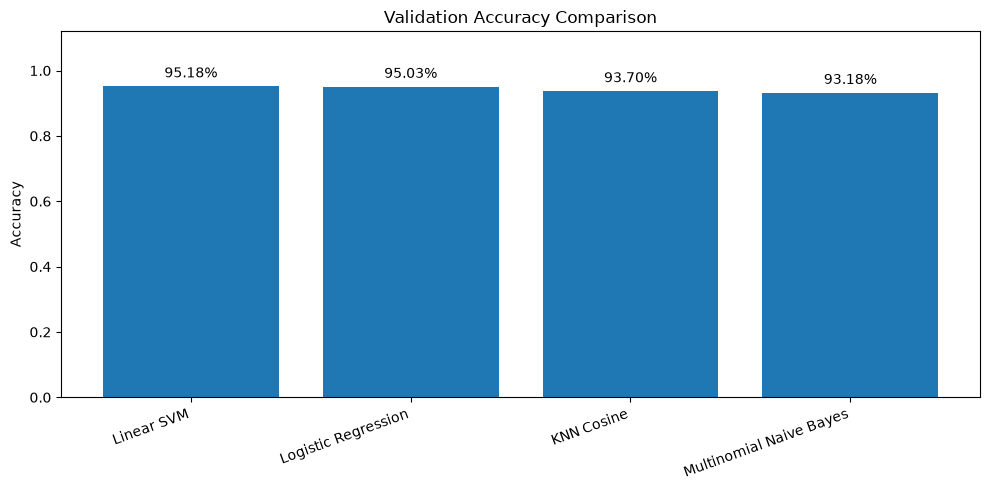


Best model by validation Macro F1: Linear SVM
Results saved in: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\traditional_ml


In [38]:

all_results = [lr_result, nb_result, svm_result, knn_result]

comparison = pd.DataFrame([
    {
        "Algorithm": r["model"],
        "Accuracy": r["validation_accuracy"],
        "Macro Precision": r["validation_precision_macro"],
        "Macro Recall": r["validation_recall_macro"],
        "Macro F1": r["validation_macro_f1"]
    }
    for r in all_results
]).sort_values("Macro F1", ascending=False)

comparison.to_csv(
    RESULTS / "validation_algorithm_comparison.csv",
    index=False
)

print("VALIDATION PERFORMANCE COMPARISON")
print(comparison.to_string(
    index=False,
    formatters={
        "Accuracy": "{:.2%}".format,
        "Macro Precision": "{:.4f}".format,
        "Macro Recall": "{:.4f}".format,
        "Macro F1": "{:.4f}".format
    }
))

# Comparison graph: all metrics
ax = comparison.set_index("Algorithm")[
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
].plot(kind="bar", figsize=(12, 6), ylim=(0, 1.08))

ax.set_title("Traditional ML Algorithms - Validation Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Algorithm")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(
    RESULTS / "validation_algorithm_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Separate accuracy comparison
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(comparison["Algorithm"], comparison["Accuracy"])
ax.set_title("Validation Accuracy Comparison")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.12)
ax.bar_label(
    bars,
    labels=[f"{score:.2%}" for score in comparison["Accuracy"]],
    padding=4
)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(
    RESULTS / "validation_accuracy_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nBest model by validation Macro F1:",
      comparison.iloc[0]["Algorithm"])
print("Results saved in:", RESULTS.resolve())



**Final Test Evaluation of the Best Traditional ML Model - Linear SVM**

LINEAR SVM - FINAL TEST RESULTS
Test Accuracy : 95.33%
Test Macro F1 : 0.9533

Test Classification Report:
              precision    recall  f1-score   support

        form       0.93      0.93      0.93       449
     invoice       0.94      0.94      0.94       449
      resume       0.99      0.99      0.99       451

    accuracy                           0.95      1349
   macro avg       0.95      0.95      0.95      1349
weighted avg       0.95      0.95      0.95      1349



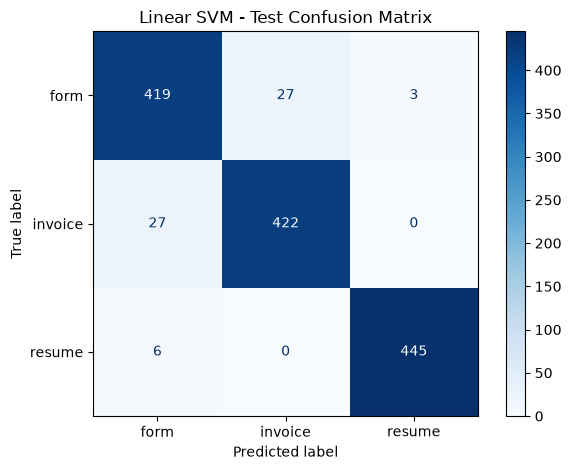

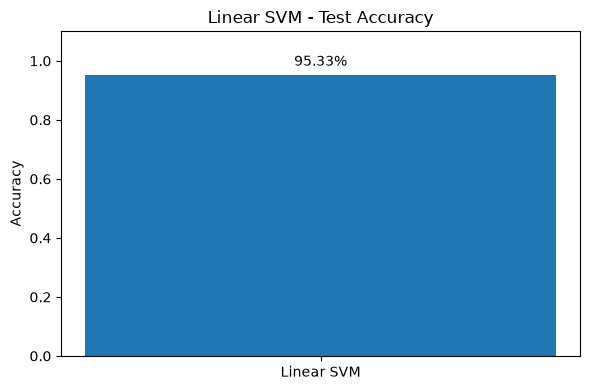


Results saved to: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\traditional_ml


In [5]:

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import load_npz
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Paths
BASE = Path("idp_outputs") / "tfidf"
RESULTS = Path("idp_outputs") / "traditional_ml"
RESULTS.mkdir(parents=True, exist_ok=True)

# Load test features and labels
X_test = load_npz(BASE / "X_test.npz")
y_test = np.load(BASE / "y_test.npy")

with open(BASE / "class_mapping.json", encoding="utf-8") as f:
    mapping = json.load(f)

classes = mapping["classes"]
class_ids = list(range(len(classes)))

# Load the saved Linear SVM model
model_path = RESULTS / "linear_svm.joblib"

if not model_path.exists():
    raise FileNotFoundError(
        f"Model not found: {model_path}. "
        "Run the Linear SVM algorithm cell first."
    )

best_model = joblib.load(model_path)

# Predict on held-out test set
y_test_pred = best_model.predict(X_test)

# Calculate metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
)

print("=" * 55)
print("LINEAR SVM - FINAL TEST RESULTS")
print("=" * 55)
print(f"Test Accuracy : {test_accuracy:.2%}")
print(f"Test Macro F1 : {test_macro_f1:.4f}")
print("\nTest Classification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=class_ids,
    target_names=classes,
    zero_division=0
))

# Graph 1: Test confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=class_ids)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Linear SVM - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    RESULTS / "linear_svm_test_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Graph 2: Test accuracy
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Linear SVM"], [test_accuracy])
ax.set_ylim(0, 1.1)
ax.set_ylabel("Accuracy")
ax.set_title("Linear SVM - Test Accuracy")
ax.bar_label(
    bars,
    labels=[f"{test_accuracy:.2%}"],
    padding=4
)
plt.tight_layout()
plt.savefig(
    RESULTS / "linear_svm_test_accuracy.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Save test metrics
with open(
    RESULTS / "linear_svm_test_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump({
        "model": "Linear SVM",
        "test_accuracy": float(test_accuracy),
        "test_macro_f1": float(test_macro_f1)
    }, f, indent=4)

# Save predictions
pd.DataFrame({
    "true_label": [classes[i] for i in y_test],
    "predicted_label": [classes[i] for i in y_test_pred]
}).to_csv(
    RESULTS / "linear_svm_test_predictions.csv",
    index=False
)

print("\nResults saved to:", RESULTS.resolve())


**Save all Traditional ML results**

In [6]:

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import load_npz
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =========================================================
# 1. PATHS AND OUTPUT FOLDERS
# =========================================================
BASE = Path("idp_outputs") / "tfidf"
RESULTS = Path("idp_outputs") / "traditional_ml"
ARCHIVE = RESULTS / "saved_results"

ARCHIVE.mkdir(parents=True, exist_ok=True)

# =========================================================
# 2. LOAD LABELS AND CLASS MAPPING
# =========================================================
y_train = np.load(BASE / "y_train.npy")
y_val = np.load(BASE / "y_validation.npy")
y_test = np.load(BASE / "y_test.npy")

X_test = load_npz(BASE / "X_test.npz")

with open(BASE / "class_mapping.json", encoding="utf-8") as f:
    mapping = json.load(f)

classes = mapping["classes"]
class_ids = list(range(len(classes)))

# =========================================================
# 3. FIND AND SAVE ALL FOUR TRAINED MODELS
# =========================================================
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Multinomial Naive Bayes": "multinomial_naive_bayes.joblib",
    "Linear SVM": "linear_svm.joblib",
    "KNN Cosine": "knn_cosine.joblib"
}

model_objects = {}
missing_models = []

for name, filename in model_files.items():
    path = RESULTS / filename

    # Prefer a model already in memory if available
    variable_name = {
        "Logistic Regression": "lr_result",
        "Multinomial Naive Bayes": "nb_result",
        "Linear SVM": "svm_result",
        "KNN Cosine": "knn_result"
    }[name]

    result = globals().get(variable_name)

    if isinstance(result, dict) and "estimator" in result:
        model = result["estimator"]
        joblib.dump(model, path)
        model_objects[name] = model
        print(f"Saved from memory: {name}")
    elif path.exists():
        model_objects[name] = joblib.load(path)
        print(f"Loaded saved model: {name}")
    else:
        missing_models.append(name)
        print(f"MODEL NOT FOUND: {name}")

# =========================================================
# 4. SAVE VALIDATION AND TEST RESULTS
# =========================================================
all_metrics = []
all_predictions = []

for name, model in model_objects.items():
    prefix = name.lower().replace(" ", "_")

    # Validation predictions
    val_pred = model.predict(
        load_npz(BASE / "X_validation.npz")
    )

    val_accuracy = accuracy_score(y_val, val_pred)
    val_precision = precision_score(
        y_val, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        y_val, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        y_val, val_pred, average="macro", zero_division=0
    )

    # Save validation report
    val_report = classification_report(
        y_val,
        val_pred,
        labels=class_ids,
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    with open(
        ARCHIVE / f"{prefix}_validation_report.json",
        "w", encoding="utf-8"
    ) as f:
        json.dump(val_report, f, indent=4)

    pd.DataFrame({
        "true_label": [classes[i] for i in y_val],
        "predicted_label": [classes[i] for i in val_pred]
    }).to_csv(
        ARCHIVE / f"{prefix}_validation_predictions.csv",
        index=False
    )

    # Save validation confusion matrix
    cm = confusion_matrix(y_val, val_pred, labels=class_ids)
    disp = ConfusionMatrixDisplay(cm, display_labels=classes)
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{name} - Validation Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        ARCHIVE / f"{prefix}_validation_confusion_matrix.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close()

    # Record validation metrics
    all_metrics.append({
        "Algorithm": name,
        "Validation Accuracy": val_accuracy,
        "Validation Macro Precision": val_precision,
        "Validation Macro Recall": val_recall,
        "Validation Macro F1": val_f1
    })

    # Test predictions and metrics
    test_pred = model.predict(X_test)

    test_accuracy = accuracy_score(y_test, test_pred)
    test_precision = precision_score(
        y_test, test_pred, average="macro", zero_division=0
    )
    test_recall = recall_score(
        y_test, test_pred, average="macro", zero_division=0
    )
    test_f1 = f1_score(
        y_test, test_pred, average="macro", zero_division=0
    )

    test_report = classification_report(
        y_test,
        test_pred,
        labels=class_ids,
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    with open(
        ARCHIVE / f"{prefix}_test_report.json",
        "w", encoding="utf-8"
    ) as f:
        json.dump(test_report, f, indent=4)

    pd.DataFrame({
        "true_label": [classes[i] for i in y_test],
        "predicted_label": [classes[i] for i in test_pred]
    }).to_csv(
        ARCHIVE / f"{prefix}_test_predictions.csv",
        index=False
    )

    cm_test = confusion_matrix(y_test, test_pred, labels=class_ids)
    disp = ConfusionMatrixDisplay(cm_test, display_labels=classes)
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{name} - Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        ARCHIVE / f"{prefix}_test_confusion_matrix.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close()

    all_metrics[-1].update({
        "Test Accuracy": test_accuracy,
        "Test Macro Precision": test_precision,
        "Test Macro Recall": test_recall,
        "Test Macro F1": test_f1
    })

    all_predictions.append({
        "Algorithm": name,
        "Validation Accuracy": val_accuracy,
        "Test Accuracy": test_accuracy,
        "Test Macro F1": test_f1
    })

    print(f"\n{name}")
    print(f"Validation Accuracy: {val_accuracy:.2%}")
    print(f"Test Accuracy:       {test_accuracy:.2%}")
    print(f"Test Macro F1:       {test_f1:.4f}")

# =========================================================
# 5. SAVE COMPARISON TABLES
# =========================================================
metrics_df = pd.DataFrame(all_metrics)
metrics_df.to_csv(
    ARCHIVE / "all_traditional_ml_metrics.csv",
    index=False
)

predictions_df = pd.DataFrame(all_predictions)
predictions_df.to_csv(
    ARCHIVE / "traditional_ml_test_summary.csv",
    index=False
)

# Validation accuracy comparison
if not metrics_df.empty:
    ax = metrics_df.set_index("Algorithm")[
        ["Validation Accuracy"]
    ].plot(kind="bar", figsize=(9, 5), ylim=(0, 1.08))

    ax.set_title("Traditional ML - Validation Accuracy")
    ax.set_ylabel("Accuracy")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(
        ARCHIVE / "validation_accuracy_comparison.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close()

    # Test accuracy comparison
    ax = metrics_df.set_index("Algorithm")[
        ["Test Accuracy"]
    ].plot(kind="bar", figsize=(9, 5), ylim=(0, 1.08))

    ax.set_title("Traditional ML - Test Accuracy")
    ax.set_ylabel("Accuracy")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(
        ARCHIVE / "test_accuracy_comparison.png",
        dpi=160, bbox_inches="tight"
    )
    plt.close()

print("\n" + "=" * 60)
print("TRADITIONAL ML SAVE SUMMARY")
print("=" * 60)
print(metrics_df.to_string(index=False))
print("\nSaved results folder:", ARCHIVE.resolve())

if missing_models:
    print("\nWARNING: These models were not found and were skipped:")
    for name in missing_models:
        print("-", name)


Loaded saved model: Logistic Regression
Loaded saved model: Multinomial Naive Bayes
Loaded saved model: Linear SVM
Loaded saved model: KNN Cosine

Logistic Regression
Validation Accuracy: 95.03%
Test Accuracy:       95.55%
Test Macro F1:       0.9556

Multinomial Naive Bayes
Validation Accuracy: 93.18%
Test Accuracy:       92.66%
Test Macro F1:       0.9266

Linear SVM
Validation Accuracy: 95.18%
Test Accuracy:       95.33%
Test Macro F1:       0.9533

KNN Cosine
Validation Accuracy: 93.70%
Test Accuracy:       94.66%
Test Macro F1:       0.9465

TRADITIONAL ML SAVE SUMMARY
              Algorithm  Validation Accuracy  Validation Macro Precision  Validation Macro Recall  Validation Macro F1  Test Accuracy  Test Macro Precision  Test Macro Recall  Test Macro F1
    Logistic Regression             0.950334                    0.950741                 0.950289             0.950458       0.955523              0.955925           0.955493       0.955649
Multinomial Naive Bayes             0.9

**DEEP LEARNING**

**ResNet18**

Model loaded: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\models\best_document_classifier.pdparams
Device: gpu
Test samples: 1349
Classes: ['form', 'invoice', 'resume']

RESNET18 - TEST RESULTS
Test accuracy : 0.8918 (89.18%)
Macro precision: 0.8947
Macro recall   : 0.8917
Macro F1       : 0.8909

Classification report:
              precision    recall  f1-score   support

        form       0.89      0.78      0.84       449
     invoice       0.83      0.93      0.88       449
      resume       0.96      0.96      0.96       451

    accuracy                           0.89      1349
   macro avg       0.89      0.89      0.89      1349
weighted avg       0.89      0.89      0.89      1349



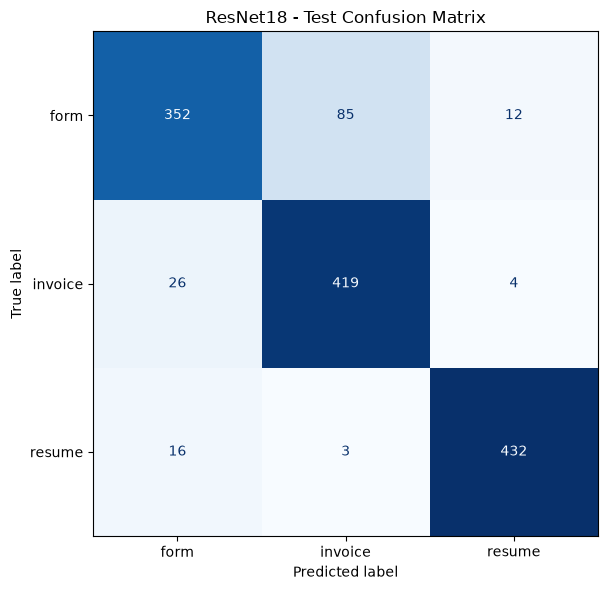

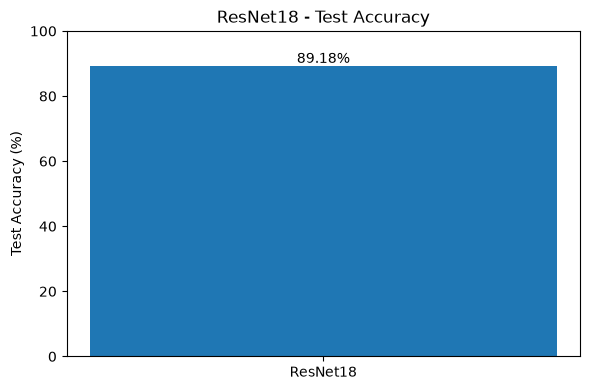

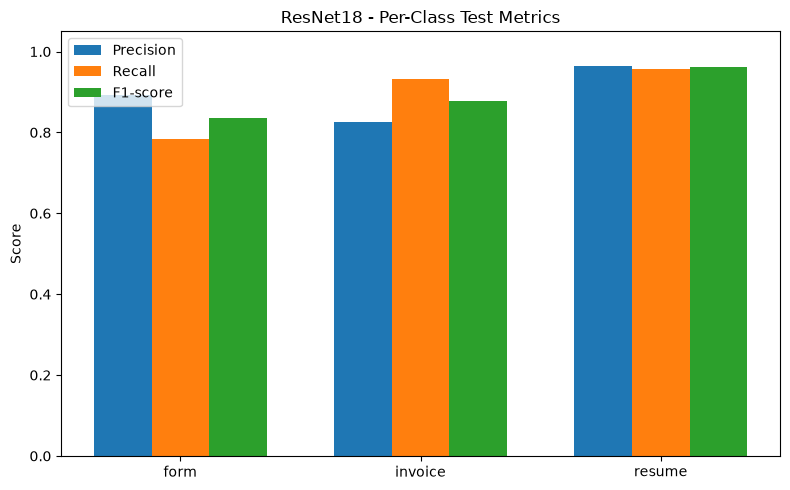


Saved results to: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\final_analysis\deep_learning
 - resnet18_test_metrics.json
 - resnet18_per_class_metrics.csv
 - resnet18_test_predictions.csv
 - resnet18_test_confusion_matrix.png
 - resnet18_test_accuracy.png
 - resnet18_test_per_class_metrics.png


In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import paddle
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------
CHECKPOINT = Path("idp_outputs/models/best_document_classifier.pdparams")
TEST_CSV = Path("/content/idp_ml_data/splits/test.csv")
OUT = Path("idp_outputs/final_analysis/deep_learning")
OUT.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224
BATCH_SIZE = 16
CLASS_NAMES = ["form", "invoice", "resume"]

if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT.resolve()}")
if not TEST_CSV.exists():
    raise FileNotFoundError(f"Test CSV not found: {TEST_CSV.resolve()}")

test_df = pd.read_csv(TEST_CSV)
required = {"image_path", "class_name"}
if not required.issubset(test_df.columns):
    raise ValueError(f"Test CSV must contain columns: {required}")

test_df = test_df[test_df["class_name"].isin(CLASS_NAMES)].reset_index(drop=True)
if test_df.empty:
    raise ValueError("No test rows found for the three expected classes.")

label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}
y_true = test_df["class_name"].map(label_to_id).to_numpy(dtype=np.int64)

missing = [p for p in test_df["image_path"] if not Path(p).exists()]
if missing:
    raise FileNotFoundError(
        f"{len(missing)} test image paths are missing. Example: {missing[0]}"
    )

# --------------------------------------------------
# 2. Load the matching ResNet18 architecture
# --------------------------------------------------
model = paddle.vision.models.resnet18(num_classes=len(CLASS_NAMES))
state = paddle.load(str(CHECKPOINT))

# Fail clearly if the checkpoint does not match this model.
try:
    model.set_state_dict(state)
except Exception as e:
    raise RuntimeError(
        "Checkpoint does not match Paddle ResNet18(num_classes=3). "
        "Use the exact model definition from the training cell."
    ) from e

device = "gpu" if paddle.device.is_compiled_with_cuda() else "cpu"
paddle.set_device(device)
model.eval()

print("Model loaded:", CHECKPOINT.resolve())
print("Device:", device)
print("Test samples:", len(test_df))
print("Classes:", CLASS_NAMES)

# --------------------------------------------------
# 3. Image preprocessing and prediction
# --------------------------------------------------
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(1, 1, 3)

def preprocess_image(path):
    with Image.open(path) as im:
        im = im.convert("RGB").resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR
        )
        arr = np.asarray(im, dtype=np.float32) / 255.0

    arr = (arr - mean) / std
    return np.transpose(arr, (2, 0, 1)).astype(np.float32)

all_probs = []

with paddle.no_grad():
    for start in range(0, len(test_df), BATCH_SIZE):
        batch_paths = test_df["image_path"].iloc[
            start:start + BATCH_SIZE
        ].tolist()

        batch = np.stack([preprocess_image(p) for p in batch_paths])
        logits = model(paddle.to_tensor(batch))
        probs = paddle.nn.functional.softmax(logits, axis=1).numpy()
        all_probs.append(probs)

probabilities = np.concatenate(all_probs, axis=0)
y_pred = probabilities.argmax(axis=1)

# --------------------------------------------------
# 4. Metrics
# --------------------------------------------------
accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=np.arange(len(CLASS_NAMES)),
    zero_division=0
)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nRESNET18 - TEST RESULTS")
print("=" * 45)
print(f"Test accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision: {macro_p:.4f}")
print(f"Macro recall   : {macro_r:.4f}")
print(f"Macro F1       : {macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0
))

# --------------------------------------------------
# 5. Save report, metrics and predictions
# --------------------------------------------------
report = classification_report(
    y_true, y_pred, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0
)

metrics = {
    "model": "ResNet18",
    "checkpoint": str(CHECKPOINT.resolve()),
    "test_samples": int(len(test_df)),
    "test_accuracy": float(accuracy),
    "macro_precision": float(macro_p),
    "macro_recall": float(macro_r),
    "macro_f1": float(macro_f1),
    "class_names": CLASS_NAMES,
    "preprocessing_assumption": (
        "RGB, 224x224, [0,1] scaling, ImageNet mean/std"
    ),
    "classification_report": report
}

with open(OUT / "resnet18_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

pd.DataFrame({
    "class": CLASS_NAMES,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
}).to_csv(OUT / "resnet18_per_class_metrics.csv", index=False)

predictions_df = test_df.copy()
predictions_df["true_label"] = [CLASS_NAMES[i] for i in y_true]
predictions_df["predicted_label"] = [CLASS_NAMES[i] for i in y_pred]
predictions_df["correct"] = y_true == y_pred

for i, name in enumerate(CLASS_NAMES):
    predictions_df[f"prob_{name}"] = probabilities[:, i]

predictions_df.to_csv(OUT / "resnet18_test_predictions.csv", index=False)

# --------------------------------------------------
# 6. Confusion matrix
# --------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("ResNet18 - Test Confusion Matrix")
fig.tight_layout()
fig.savefig(OUT / "resnet18_test_confusion_matrix.png", dpi=300)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 7. Accuracy graph
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["ResNet18"], [accuracy * 100])
ax.set_ylim(0, 100)
ax.set_ylabel("Test Accuracy (%)")
ax.set_title("ResNet18 - Test Accuracy")
ax.bar_label(ax.containers[0], fmt="%.2f%%")
fig.tight_layout()
fig.savefig(OUT / "resnet18_test_accuracy.png", dpi=300)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 8. Per-class metrics graph
# --------------------------------------------------
x = np.arange(len(CLASS_NAMES))
width = 0.24

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width, precision, width, label="Precision")
ax.bar(x, recall, width, label="Recall")
ax.bar(x + width, f1, width, label="F1-score")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("ResNet18 - Per-Class Test Metrics")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "resnet18_test_per_class_metrics.png", dpi=300)
plt.show()
plt.close(fig)

print("\nSaved results to:", OUT.resolve())
print(" - resnet18_test_metrics.json")
print(" - resnet18_per_class_metrics.csv")
print(" - resnet18_test_predictions.csv")
print(" - resnet18_test_confusion_matrix.png")
print(" - resnet18_test_accuracy.png")
print(" - resnet18_test_per_class_metrics.png")

**MobileNetV2**

Device: gpu
Train: 6294
Validation: 1349
Test: 1349


c:\Users\ashis\anaconda3\envs\idp_env\Lib\site-packages\paddle\nn\layer\norm.py:818: UserWarning: When training, we now always track global mean and variance.
  warnings.warn(


Epoch 1/8 | train_loss=0.9220 | train_acc=0.5442 | val_loss=0.8293 | val_acc=0.6294
  Saved best validation checkpoint.


c:\Users\ashis\anaconda3\envs\idp_env\Lib\site-packages\paddle\nn\layer\norm.py:818: UserWarning: When training, we now always track global mean and variance.
  warnings.warn(


Epoch 2/8 | train_loss=0.7334 | train_acc=0.6671 | val_loss=0.6717 | val_acc=0.7109
  Saved best validation checkpoint.


c:\Users\ashis\anaconda3\envs\idp_env\Lib\site-packages\paddle\nn\layer\norm.py:818: UserWarning: When training, we now always track global mean and variance.
  warnings.warn(


... (7 outputs left out)

c:\Users\ashis\anaconda3\envs\idp_env\Lib\site-packages\paddle\nn\layer\norm.py:818: UserWarning: When training, we now always track global mean and variance.
  warnings.warn(


Epoch 7/8 | train_loss=0.4373 | train_acc=0.8240 | val_loss=0.6403 | val_acc=0.7457


c:\Users\ashis\anaconda3\envs\idp_env\Lib\site-packages\paddle\nn\layer\norm.py:818: UserWarning: When training, we now always track global mean and variance.
  warnings.warn(


Epoch 8/8 | train_loss=0.3861 | train_acc=0.8507 | val_loss=0.6158 | val_acc=0.7576

MOBILENETV2 — TEST RESULTS
Test accuracy: 0.7784 (77.84%)
Macro precision: 0.7846
Macro recall: 0.7782
Macro F1: 0.7806
              precision    recall  f1-score   support

        form       0.69      0.72      0.71       449
     invoice       0.73      0.76      0.74       449
      resume       0.93      0.85      0.89       451

    accuracy                           0.78      1349
   macro avg       0.78      0.78      0.78      1349
weighted avg       0.78      0.78      0.78      1349



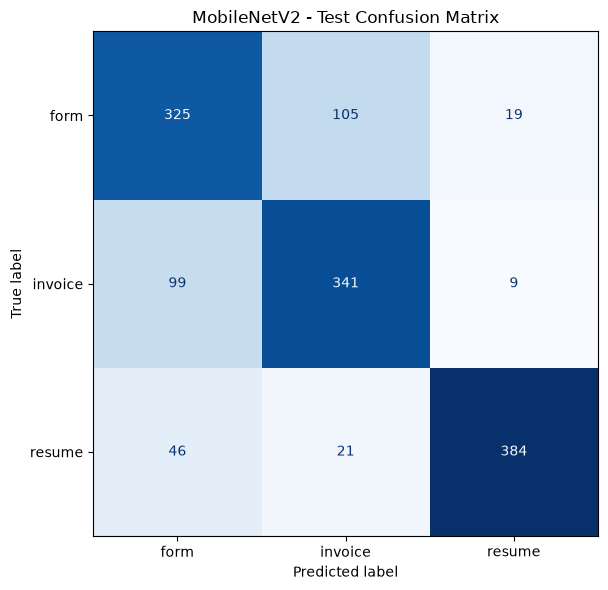

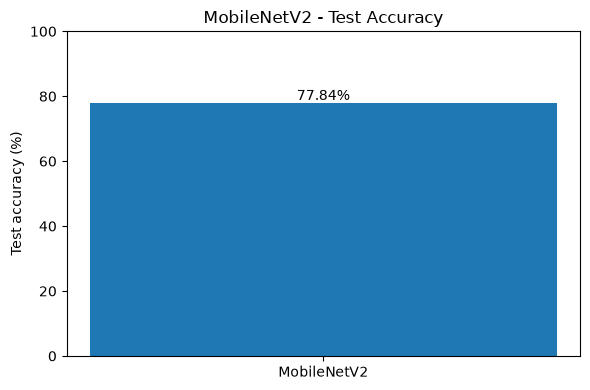

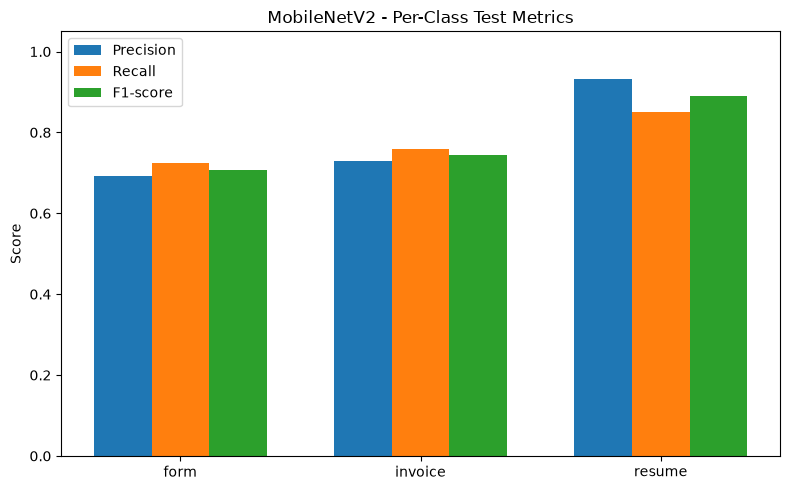


Elapsed minutes: 19.8
Saved results to: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\final_analysis\mobilenet_v2
Best checkpoint: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\final_analysis\mobilenet_v2\best_mobilenet_v2.pdparams


In [11]:

from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import paddle
import matplotlib.pyplot as plt

from PIL import Image
from paddle.vision.models import mobilenet_v2
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
ROOT = Path("/content/idp_ml_data/splits")
OUT = Path("idp_outputs/final_analysis/mobilenet_v2")
OUT.mkdir(parents=True, exist_ok=True)

CLASSES = ["form", "invoice", "resume"]
SIZE = 224
BATCH_SIZE = 16
EPOCHS = 8
LR = 0.0001
SEED = 42

paddle.seed(SEED)
np.random.seed(SEED)

device = "gpu" if paddle.device.is_compiled_with_cuda() else "cpu"
paddle.set_device(device)

# --------------------------------------------------
# 2. Load existing split CSVs
# --------------------------------------------------
def load_split(filename):
    df = pd.read_csv(ROOT / filename)
    df = df[df["class_name"].isin(CLASSES)].reset_index(drop=True)

    if df.empty:
        raise ValueError(f"No matching samples in {filename}")

    missing = [p for p in df["image_path"] if not Path(p).exists()]
    if missing:
        raise FileNotFoundError(f"Missing image: {missing[0]}")

    df["label"] = df["class_name"].map(
        {name: i for i, name in enumerate(CLASSES)}
    )
    return df

train_df = load_split("train.csv")
val_df = load_split("validation.csv")
test_df = load_split("test.csv")

print("Device:", device)
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# --------------------------------------------------
# 3. Image preprocessing
# --------------------------------------------------
mean = np.array([0.485, 0.456, 0.406], np.float32).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225], np.float32).reshape(1, 1, 3)

def preprocess(path):
    with Image.open(path) as im:
        im = im.convert("RGB").resize(
            (SIZE, SIZE), Image.Resampling.BILINEAR
        )
        arr = np.asarray(im, dtype=np.float32) / 255.0

    arr = (arr - mean) / std
    return np.transpose(arr, (2, 0, 1)).astype(np.float32)

def make_batch(df, start, end):
    images = np.stack([
        preprocess(p) for p in df["image_path"].iloc[start:end]
    ])
    labels = df["label"].iloc[start:end].to_numpy(dtype=np.int64)
    return paddle.to_tensor(images), paddle.to_tensor(labels)

# --------------------------------------------------
# 4. Build MobileNetV2
# --------------------------------------------------
model = mobilenet_v2(num_classes=len(CLASSES))

loss_fn = paddle.nn.CrossEntropyLoss()
optimizer = paddle.optimizer.Adam(
    learning_rate=LR, parameters=model.parameters()
)

best_val_accuracy = -1.0
history = []
checkpoint = OUT / "best_mobilenet_v2.pdparams"

# --------------------------------------------------
# 5. Train and select best validation checkpoint
# --------------------------------------------------
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    order = np.random.permutation(len(train_df))
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for start in range(0, len(order), BATCH_SIZE):
        idx = order[start:start + BATCH_SIZE]
        batch_df = train_df.iloc[idx]

        x, y = make_batch(batch_df, 0, len(batch_df))
        logits = model(x)
        loss = loss_fn(logits, y)

        loss.backward()
        optimizer.step()
        optimizer.clear_grad()

        n = len(batch_df)
        train_loss_sum += float(loss.numpy().item()) * n
        train_correct += int((logits.argmax(axis=1) == y).sum().item())
        train_count += n

    model.eval()
    val_true, val_pred = [], []
    val_loss_sum = 0.0

    with paddle.no_grad():
        for start in range(0, len(val_df), BATCH_SIZE):
            end = min(start + BATCH_SIZE, len(val_df))
            x, y = make_batch(val_df, start, end)
            logits = model(x)
            loss = loss_fn(logits, y)

            val_loss_sum += float(loss.numpy().item()) * (end - start)
            val_true.extend(y.numpy().tolist())
            val_pred.extend(logits.argmax(axis=1).numpy().tolist())

    train_accuracy = train_correct / train_count
    train_loss = train_loss_sum / train_count
    val_accuracy = accuracy_score(val_true, val_pred)
    val_loss = val_loss_sum / len(val_df)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | "
        f"train_acc={train_accuracy:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_acc={val_accuracy:.4f}"
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        paddle.save(model.state_dict(), str(checkpoint))
        print("  Saved best validation checkpoint.")

pd.DataFrame(history).to_csv(OUT / "training_history.csv", index=False)

# --------------------------------------------------
# 6. Load best checkpoint and evaluate test set
# --------------------------------------------------
model.set_state_dict(paddle.load(str(checkpoint)))
model.eval()

y_true, y_pred, probabilities = [], [], []

with paddle.no_grad():
    for start in range(0, len(test_df), BATCH_SIZE):
        end = min(start + BATCH_SIZE, len(test_df))
        x, y = make_batch(test_df, start, end)

        logits = model(x)
        probs = paddle.nn.functional.softmax(logits, axis=1)

        y_true.extend(y.numpy().tolist())
        y_pred.extend(probs.argmax(axis=1).numpy().tolist())
        probabilities.extend(probs.numpy().tolist())

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
probabilities = np.asarray(probabilities)

accuracy = accuracy_score(y_true, y_pred)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=np.arange(len(CLASSES)), zero_division=0
)

report_text = classification_report(
    y_true, y_pred, labels=np.arange(len(CLASSES)),
    target_names=CLASSES, zero_division=0
)

print("\nMOBILENETV2 — TEST RESULTS")
print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision: {macro_p:.4f}")
print(f"Macro recall: {macro_r:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(report_text)

with open(OUT / "mobilenet_v2_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump({
        "model": "MobileNetV2",
        "device": device,
        "test_samples": len(test_df),
        "best_validation_accuracy": best_val_accuracy,
        "test_accuracy": accuracy,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "class_names": CLASSES,
        "classification_report": classification_report(
            y_true, y_pred, labels=np.arange(len(CLASSES)),
            target_names=CLASSES, output_dict=True, zero_division=0
        )
    }, f, indent=2)

pd.DataFrame({
    "class": CLASSES,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
}).to_csv(OUT / "mobilenet_v2_per_class_metrics.csv", index=False)

pred_df = test_df.copy()
pred_df["true_label"] = [CLASSES[i] for i in y_true]
pred_df["predicted_label"] = [CLASSES[i] for i in y_pred]
pred_df["correct"] = y_true == y_pred

for i, name in enumerate(CLASSES):
    pred_df[f"prob_{name}"] = probabilities[:, i]

pred_df.to_csv(OUT / "mobilenet_v2_test_predictions.csv", index=False)

# --------------------------------------------------
# 7. Save graphs
# --------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASSES)))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_title("MobileNetV2 - Test Confusion Matrix")
fig.tight_layout()
fig.savefig(OUT / "mobilenet_v2_confusion_matrix.png", dpi=300)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["MobileNetV2"], [accuracy * 100])
ax.set_ylim(0, 100)
ax.set_ylabel("Test accuracy (%)")
ax.set_title("MobileNetV2 - Test Accuracy")
ax.bar_label(ax.containers[0], fmt="%.2f%%")
fig.tight_layout()
fig.savefig(OUT / "mobilenet_v2_accuracy.png", dpi=300)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(CLASSES))
width = 0.24
ax.bar(x - width, precision, width, label="Precision")
ax.bar(x, recall, width, label="Recall")
ax.bar(x + width, f1, width, label="F1-score")
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("MobileNetV2 - Per-Class Test Metrics")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "mobilenet_v2_per_class_metrics.png", dpi=300)
plt.show()
plt.close(fig)

print(f"\nElapsed minutes: {(time.time() - start_time) / 60:.1f}")
print("Saved results to:", OUT.resolve())
print("Best checkpoint:", checkpoint.resolve())


**EfficientNet-B0**

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
GPU memory: 4.00 GB
Train samples:      6294
Validation samples: 1349
Test samples:       1349

Training class counts:
class_name
form       2096
invoice    2094
resume     2104
Name: count, dtype: int64
Epoch 1/8 | Train Loss: 0.8491 | Train Acc: 0.5793 | Val Loss: 1.0135 | Val Acc: 0.6442
  Best checkpoint saved.
Epoch 2/8 | Train Loss: 0.6633 | Train Acc: 0.6978 | Val Loss: 0.6666 | Val Acc: 0.7317
  Best checkpoint saved.
Epoch 3/8 | Train Loss: 0.5701 | Train Acc: 0.7545 | Val Loss: 0.5878 | Val Acc: 0.7583
  Best checkpoint saved.
Epoch 4/8 | Train Loss: 0.4944 | Train Acc: 0.7866 | Val Loss: 0.5237 | Val Acc: 0.7991
  Best checkpoint saved.
Epoch 5/8 | Train Loss: 0.4227 | Train Acc: 0.8287 | Val Loss: 0.5683 | Val Acc: 0.7887
Epoch 6/8 | Train Loss: 0.3603 | Train Acc: 0.8551 | Val Loss: 0.5156 | Val Acc: 0.8006
  Best checkpoint saved.
Epoch 7/8 | Train Loss: 0.3001 | Train Acc: 0.8837 | Val Loss: 0.5530 | Val Acc: 0.7895
Ep

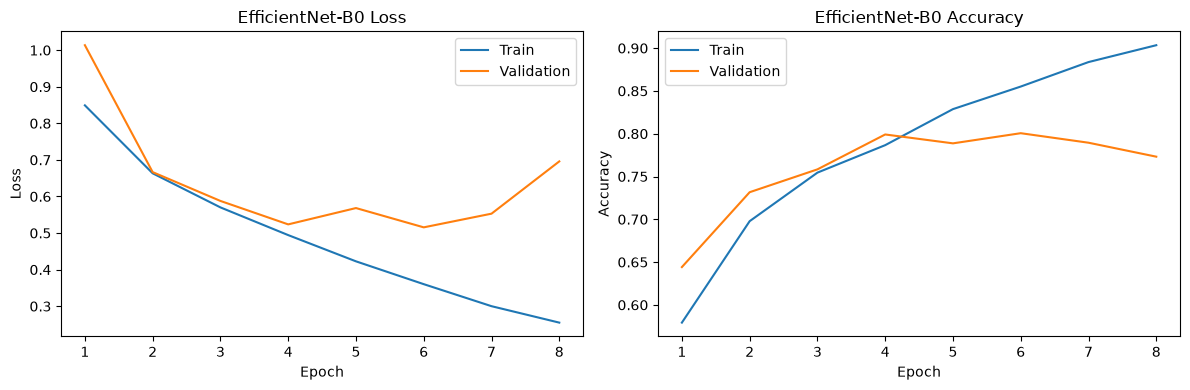


Best epoch: 6
Best validation accuracy: 0.8006

EFFICIENTNET-B0 — TEST RESULTS
Test accuracy:  0.8043 (80.43%)
Macro precision: 0.8060
Macro recall:    0.8041
Macro F1-score:  0.8000

Classification report:
              precision    recall  f1-score   support

        form       0.82      0.64      0.72       449
     invoice       0.73      0.83      0.78       449
      resume       0.87      0.95      0.91       451

    accuracy                           0.80      1349
   macro avg       0.81      0.80      0.80      1349
weighted avg       0.81      0.80      0.80      1349



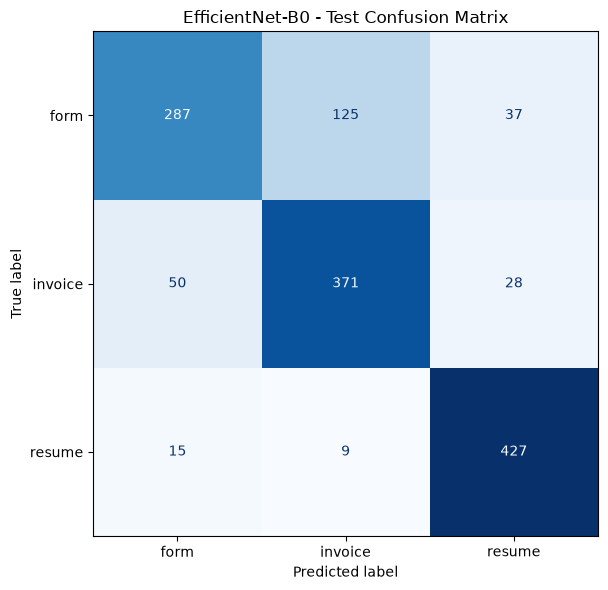

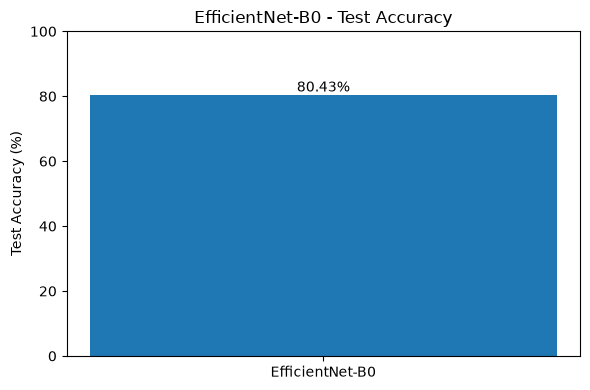

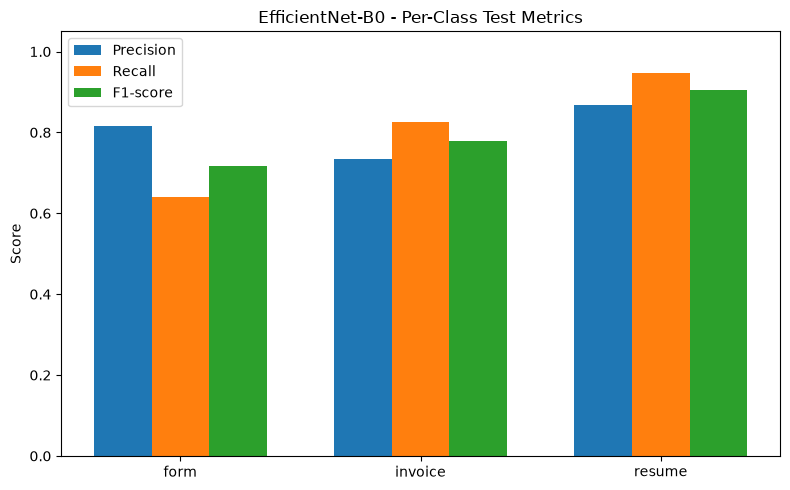


Elapsed time: 19.4 minutes
Results folder: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\final_analysis\efficientnet_b0
Best checkpoint: C:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\final_analysis\efficientnet_b0\best_efficientnet_b0.pth
Peak GPU memory allocated: 0.74 GB


In [1]:

from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =====================================================
# 1. Configuration
# =====================================================
SPLIT_DIR = Path("/content/idp_ml_data/splits")
OUT = Path("idp_outputs/final_analysis/efficientnet_b0")
OUT.mkdir(parents=True, exist_ok=True)

CLASSES = ["form", "invoice", "resume"]
IMAGE_SIZE = 224
BATCH_SIZE = 8
EPOCHS = 8
LEARNING_RATE = 0.0001
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# =====================================================
# 2. Load and validate existing splits
# =====================================================
def load_split(filename):
    path = SPLIT_DIR / filename

    if not path.exists():
        raise FileNotFoundError(f"Split file not found: {path.resolve()}")

    df = pd.read_csv(path)

    required = {"image_path", "class_name"}
    if not required.issubset(df.columns):
        raise ValueError(
            f"{filename} must contain columns: {sorted(required)}"
        )

    df = df[df["class_name"].isin(CLASSES)].copy().reset_index(drop=True)

    if df.empty:
        raise ValueError(f"No matching samples found in {filename}")

    df["label"] = df["class_name"].map(
        {name: i for i, name in enumerate(CLASSES)}
    ).astype(int)

    missing = [p for p in df["image_path"] if not Path(p).is_file()]
    if missing:
        raise FileNotFoundError(f"Missing image file: {missing[0]}")

    return df


train_df = load_split("train.csv")
val_df = load_split("validation.csv")
test_df = load_split("test.csv")

print(f"Train samples:      {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples:       {len(test_df)}")

print("\nTraining class counts:")
print(train_df["class_name"].value_counts().reindex(CLASSES, fill_value=0))

# =====================================================
# 3. Image preprocessing
# =====================================================
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class DocumentDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = image_transform(img.convert("RGB"))

        return image, int(row["label"])


pin_memory = DEVICE.type == "cuda"

train_loader = DataLoader(
    DocumentDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=pin_memory
)

val_loader = DataLoader(
    DocumentDataset(val_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    DocumentDataset(test_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory
)

# =====================================================
# 4. Build EfficientNet-B0
# =====================================================
# Training from scratch, without pretrained weights.
model = models.efficientnet_b0(weights=None)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(CLASSES))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

checkpoint = OUT / "best_efficientnet_b0.pth"
history = []
best_val_accuracy = -1.0
best_epoch = 0
start_time = time.time()

# =====================================================
# 5. Train and select best validation checkpoint
# =====================================================
for epoch in range(1, EPOCHS + 1):
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=pin_memory)
        labels = labels.to(DEVICE, non_blocking=pin_memory)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        count = labels.size(0)
        train_loss_sum += loss.item() * count
        train_correct += (logits.argmax(dim=1) == labels).sum().item()
        train_count += count

    train_loss = train_loss_sum / train_count
    train_accuracy = train_correct / train_count

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=pin_memory)
            labels = labels.to(DEVICE, non_blocking=pin_memory)

            logits = model(images)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(logits.argmax(dim=1).cpu().tolist())

    val_loss = val_loss_sum / len(val_df)
    val_accuracy = accuracy_score(val_true, val_pred)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # Save only the best validation checkpoint
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch

        torch.save({
            "model_state_dict": model.state_dict(),
            "best_epoch": best_epoch,
            "best_validation_accuracy": best_val_accuracy,
            "classes": CLASSES
        }, checkpoint)

        print("  Best checkpoint saved.")

    # Release references to batch tensors
    del images, labels, logits, loss

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(
    OUT / "efficientnet_b0_training_history.csv",
    index=False
)

# =====================================================
# 6. Plot training curves
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation"
)
axes[0].set_title("EfficientNet-B0 Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Train"
)
axes[1].plot(
    history_df["epoch"],
    history_df["validation_accuracy"],
    label="Validation"
)
axes[1].set_title("EfficientNet-B0 Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

fig.tight_layout()
fig.savefig(OUT / "efficientnet_b0_training_curves.png", dpi=300)
plt.show()
plt.close(fig)

# =====================================================
# 7. Load best checkpoint
# =====================================================
if not checkpoint.exists():
    raise FileNotFoundError("Training did not produce a checkpoint.")

saved_checkpoint = torch.load(
    checkpoint,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(saved_checkpoint["model_state_dict"])
model.eval()

print(f"\nBest epoch: {saved_checkpoint['best_epoch']}")
print(
    "Best validation accuracy: "
    f"{saved_checkpoint['best_validation_accuracy']:.4f}"
)

# =====================================================
# 8. Evaluate on test set
# =====================================================
y_true = []
y_pred = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=pin_memory)

        logits = model(images)
        probs = torch.softmax(logits, dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(probs.argmax(dim=1).cpu().tolist())
        all_probs.extend(probs.cpu().tolist())

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
all_probs = np.asarray(all_probs)

accuracy = accuracy_score(y_true, y_pred)

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(len(CLASSES)),
    average="macro",
    zero_division=0
)

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(len(CLASSES)),
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

print("\nEFFICIENTNET-B0 — TEST RESULTS")
print("=" * 45)
print(f"Test accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision: {macro_p:.4f}")
print(f"Macro recall:    {macro_r:.4f}")
print(f"Macro F1-score:  {macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    zero_division=0
))

# Save metrics JSON
metrics = {
    "model": "EfficientNet-B0",
    "framework": "PyTorch",
    "device": str(DEVICE),
    "epochs_configured": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "pretrained_weights": False,
    "best_epoch": int(saved_checkpoint["best_epoch"]),
    "best_validation_accuracy": float(
        saved_checkpoint["best_validation_accuracy"]
    ),
    "test_samples": int(len(test_df)),
    "test_accuracy": float(accuracy),
    "macro_precision": float(macro_p),
    "macro_recall": float(macro_r),
    "macro_f1": float(macro_f1),
    "class_names": CLASSES,
    "classification_report": report_dict
}

with open(
    OUT / "efficientnet_b0_test_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=2)

# Save per-class metrics
pd.DataFrame({
    "class": CLASSES,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
}).to_csv(
    OUT / "efficientnet_b0_per_class_metrics.csv",
    index=False
)

# Save predictions and class probabilities
pred_df = test_df.copy()
pred_df["true_label"] = [CLASSES[i] for i in y_true]
pred_df["predicted_label"] = [CLASSES[i] for i in y_pred]
pred_df["correct"] = y_true == y_pred

for i, name in enumerate(CLASSES):
    pred_df[f"prob_{name}"] = all_probs[:, i]

pred_df.to_csv(
    OUT / "efficientnet_b0_test_predictions.csv",
    index=False
)

# =====================================================
# 9. Save confusion matrix
# =====================================================
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(CLASSES))
)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("EfficientNet-B0 - Test Confusion Matrix")
fig.tight_layout()
fig.savefig(OUT / "efficientnet_b0_confusion_matrix.png", dpi=300)
plt.show()
plt.close(fig)

# =====================================================
# 10. Save test accuracy graph
# =====================================================
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["EfficientNet-B0"], [accuracy * 100])

ax.set_ylim(0, 100)
ax.set_ylabel("Test Accuracy (%)")
ax.set_title("EfficientNet-B0 - Test Accuracy")
ax.bar_label(bars, fmt="%.2f%%")

fig.tight_layout()
fig.savefig(OUT / "efficientnet_b0_accuracy.png", dpi=300)
plt.show()
plt.close(fig)

# =====================================================
# 11. Save per-class metrics graph
# =====================================================
x = np.arange(len(CLASSES))
width = 0.24

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width, precision, width, label="Precision")
ax.bar(x, recall, width, label="Recall")
ax.bar(x + width, f1, width, label="F1-score")

ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("EfficientNet-B0 - Per-Class Test Metrics")
ax.legend()

fig.tight_layout()
fig.savefig(OUT / "efficientnet_b0_per_class_metrics.png", dpi=300)
plt.show()
plt.close(fig)

# =====================================================
# 12. Finish
# =====================================================
elapsed_minutes = (time.time() - start_time) / 60

print(f"\nElapsed time: {elapsed_minutes:.1f} minutes")
print("Results folder:", OUT.resolve())
print("Best checkpoint:", checkpoint.resolve())

if DEVICE.type == "cuda":
    print(
        f"Peak GPU memory allocated: "
        f"{torch.cuda.max_memory_allocated() / (1024**3):.2f} GB"
    )
    torch.cuda.empty_cache()


**Comparative Performance Analysis of ResNet18, MobileNetV2, and EfficientNet-B0 for Document Classification**

,Model,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1
0,ResNet18,89.18,0.8947,0.8917,0.8909
1,EfficientNet-B0,80.43,0.8060,0.8041,0.8000
2,MobileNetV2,77.84,0.7846,0.7782,0.7806


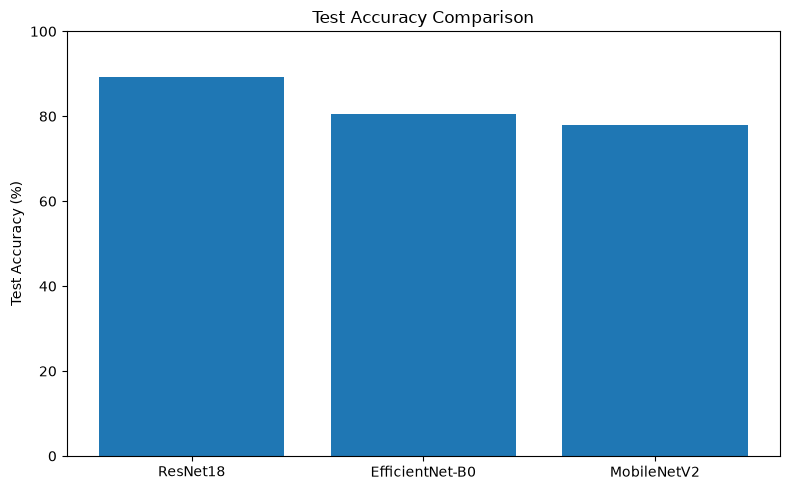

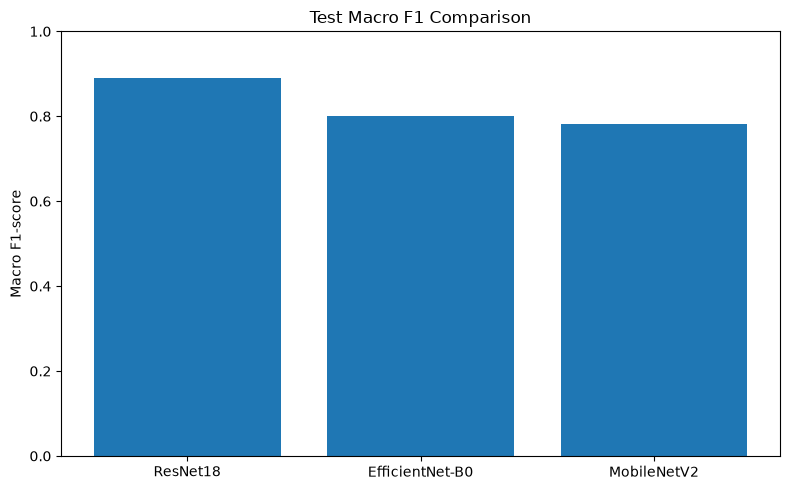

Best by test Macro F1: ResNet18 (0.8909)

Comparison saved to: c:\Users\ashis\OneDrive\Desktop\idp project\idp_outputs\final_comparison


In [2]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Find saved test-metric files under the current project folder
ROOT = Path.cwd()
OUTPUT_DIR = ROOT / "idp_outputs" / "final_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

search_roots = [ROOT / "idp_outputs"]
if not search_roots[0].exists():
    search_roots = [ROOT]

all_json_files = [
    p for base in search_roots if base.exists()
    for p in base.rglob("*test_metrics.json")
]

model_patterns = {
    "ResNet18": ["resnet18"],
    "MobileNetV2": ["mobilenet_v2", "mobilenetv2"],
    "EfficientNet-B0": ["efficientnet_b0", "efficientnet-b0", "efficientnet"],
}

def find_file(patterns):
    matches = [
        p for p in all_json_files
        if any(pattern in str(p).lower() for pattern in patterns)
    ]
    return matches[0] if matches else None

def metric_value(data, keys):
    for key in keys:
        if data.get(key) is not None:
            return float(data[key])
    report = data.get("classification_report", data.get("report", {}))
    if isinstance(report, dict):
        macro = report.get("macro avg", report.get("macro_avg", {}))
        if isinstance(macro, dict):
            for key in keys:
                if key in macro:
                    return float(macro[key])
    return None

rows = []
missing = []

for model, patterns in model_patterns.items():
    path = find_file(patterns)

    if path is None:
        missing.append(model)
        continue

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    accuracy = metric_value(data, ["test_accuracy", "accuracy", "test_acc"])
    precision = metric_value(data, ["macro_precision", "test_macro_precision", "precision"])
    recall = metric_value(data, ["macro_recall", "test_macro_recall", "recall"])
    f1 = metric_value(data, ["macro_f1", "test_macro_f1", "f1-score", "f1_score"])

    rows.append({
        "Model": model,
        "Test Accuracy (%)": (
            round(accuracy * 100 if accuracy is not None and accuracy <= 1 else accuracy, 2)
            if accuracy is not None else None
        ),
        "Macro Precision": round(precision, 4) if precision is not None else None,
        "Macro Recall": round(recall, 4) if recall is not None else None,
        "Macro F1": round(f1, 4) if f1 is not None else None,
        "Metrics File": str(path),
    })

if not rows:
    raise FileNotFoundError(
        "No matching test metrics were found. Check the output folders and JSON filenames."
    )

comparison = pd.DataFrame(rows)
comparison = comparison.sort_values(
    "Macro F1", ascending=False, na_position="last"
).reset_index(drop=True)

display(comparison.drop(columns="Metrics File"))

comparison.to_csv(OUTPUT_DIR / "three_dl_models_test_comparison.csv", index=False)
comparison.drop(columns="Metrics File").to_json(
    OUTPUT_DIR / "three_dl_models_test_comparison.json",
    orient="records",
    indent=2
)

# Accuracy plot
acc = comparison.dropna(subset=["Test Accuracy (%)"])
if not acc.empty:
    plt.figure(figsize=(8, 5))
    plt.bar(acc["Model"], acc["Test Accuracy (%)"])
    plt.ylabel("Test Accuracy (%)")
    plt.title("Test Accuracy Comparison")
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "test_accuracy_comparison.png", dpi=300)
    plt.show()
    plt.close()

# Macro F1 plot
f1_data = comparison.dropna(subset=["Macro F1"])
if not f1_data.empty:
    plt.figure(figsize=(8, 5))
    plt.bar(f1_data["Model"], f1_data["Macro F1"])
    plt.ylabel("Macro F1-score")
    plt.title("Test Macro F1 Comparison")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "test_macro_f1_comparison.png", dpi=300)
    plt.show()
    plt.close()

if not f1_data.empty:
    best = f1_data.iloc[0]
    print(
        f"Best by test Macro F1: {best['Model']} "
        f"({best['Macro F1']:.4f})"
    )

if missing:
    print("\nTest metrics file not found for:", ", ".join(missing))
    print("Check each model's saved test_metrics.json path before drawing conclusions.")

print(f"\nComparison saved to: {OUTPUT_DIR}")